# Wind Speed Forecasting — Two-Stage LSTM Feature Extraction + ML Regressors

**Framework:** Dataset → Preprocessing → Split (80% train / 20% validation + 1 held-out week) →
**LSTM feature extraction** (input 168 × 7 → LSTM 128 → Dropout 20% → Dense 64) →
six regressors (Linear, Lasso, Ridge, SVR, Decision Tree, ANN) → Evaluation (RMSE, MSE, MAE, R²) → Deployment.

**Sebelum mulai:** `Runtime → Change runtime type → GPU (T4)` agar training LSTM cepat.

Semua gambar disimpan ke folder `figures/` dalam tiga format: **PNG 600 dpi**, **TIFF 600 dpi (LZW)** dan **PDF vektor** —
sesuai persyaratan umum jurnal Q1 (Elsevier, Springer, MDPI, IEEE).

## 1. Setup & library

In [1]:
import os, json, random, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib
warnings.filterwarnings("ignore")

try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("TensorFlow :", tf.__version__)
print("GPU        :", tf.config.list_physical_devices("GPU") or "tidak ada (pakai CPU)")
print("Colab      :", IN_COLAB)

TensorFlow : 2.21.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Colab      : True


## 2. Konfigurasi
Sesuaikan nama kolom dengan header CSV Anda. Input LSTM = **168 jam (7 hari × 24 jam) × jumlah variabel**:
9 variabel meteorologi (168 × 9), atau 168 × 10 bila wind speed historis ikut sebagai input.

In [2]:
# ---------- Sumber data (Google Drive) ----------
CSV_PATH = "/content/drive/MyDrive/AI & Data/Wind Prediction/Wufeng-District.csv"
CSV_SEP  = ";"            # pemisah kolom pada file Anda
# Desimal koma ("2,57") otomatis diubah menjadi titik ("2.57") saat membaca data.

# ---------- Kolom ----------
DATETIME_COL = "dt_iso"
TARGET_COL   = "wind_speed"                        # variabel yang diprediksi
# Semua variabel meteorologi yang terisi 100% (total 10 parameter bersama wind_speed).
# Kolom lain tidak dipakai: dt/timezone/lat/lon/city_name (identitas/konstan),
# sea_level/grnd_level/snow_* (0% terisi), rain_3h (0.2%), visibility (12%), wind_gust (15%),
# rain_1h (16%), weather_* (kategori turunan dari awan/hujan).
FEATURE_COLS = ["temp", "dew_point", "feels_like", "temp_min", "temp_max",
                "pressure", "humidity", "wind_deg", "clouds_all"]
WIND_DEG_SINCOS = False   # True: arah angin -> sin & cos

# ---------- Skenario input ----------
# False: input hanya variabel meteorologi (wind speed TIDAK ikut sebagai input) -> 168 x 9
# True : wind speed historis ikut sebagai input (autoregresif)                -> 168 x 10
USE_TARGET_HISTORY = False

# ---------- Batas kualitas data (notebook berhenti bila dilanggar) ----------
MAX_TARGET_MISSING  = 0.20   # maks. 20% wind speed kosong setelah dibaca
MAX_FEATURE_MISSING = 0.50   # fitur dengan > 50% kosong otomatis dikeluarkan
MIN_TEST_REAL_OBS   = 0.90   # min. 90% target minggu uji harus data asli (bukan interpolasi)

# ---------- Kriteria keputusan fit (tabel pengujian) ----------
OVERFIT_GAP = 0.30    # Overfit bila (RMSE_test - RMSE_train) / RMSE_test > 30%
UNDERFIT_R2 = 0.10    # Underfit bila R2 training < 0.10

# ---------- Jendela & split ----------
WINDOW      = 168          # 7 hari x 24 jam  (Input Layer 168 x n_variabel)
HORIZON     = 1            # prediksi 1 jam ke depan
TRAIN_RATIO = 0.80
TEST_START  = "2023-04-01"
TEST_END    = "2023-04-07"

# ---------- Arsitektur LSTM (sesuai gambar) ----------
LSTM_UNITS   = 128
DROPOUT      = 0.20
DENSE_UNITS  = 64          # = dimensi fitur hasil ekstraksi (Output LSTM 64 units)
EPOCHS       = 100
BATCH_SIZE   = 64
LR           = 1e-3

# ---------- Wind power (ganti dengan spesifikasi turbin yang dipakai) ----------
MEAS_HEIGHT   = 10.0     # tinggi anemometer (m)
HUB_HEIGHT    = 30.0     # tinggi hub turbin (m)
SHEAR_ALPHA   = 1 / 7    # eksponen power-law profil angin (0.143 untuk medan terbuka)
TURBINE = dict(name="Example small wind turbine",   # CONTOH — ganti sesuai datasheet turbin
               cut_in=2.5, rated_speed=11.0, cut_out=25.0, rated_power_kw=20.0)
POWER_CURVE_CSV = None   # opsional: CSV pabrikan dengan kolom speed (m/s), power_kw -> menggantikan rumus
X_AXIS = "datetime"      # "datetime" (tanggal) atau "index" (Data points) untuk gambar deret waktu

# ---------- Preprocessing ----------
PHYSICAL_LIMITS = {"wind_speed": (0, 60), "temp": (-20, 50), "feels_like": (-30, 60),
                   "temp_min": (-20, 50), "temp_max": (-20, 50),
                   "wind_deg": (0, 360), "humidity": (0, 100), "clouds": (0, 100), "clouds_all": (0, 100),
                   "pressure": (900, 1100), "dew_point": (-30, 40)}
IQR_K = 3.0
MAX_INTERP_GAP = 6         # jam

SEED    = 42
OUT_DIR = "results"
FIG_DIR = f"{OUT_DIR}/figures"
os.makedirs(FIG_DIR, exist_ok=True)

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

## 2b. Log & environment
Semua output `print` (termasuk log training per epoch) ikut disimpan ke `results/logs/run_log_<waktu>.txt`.
Environment (versi Python & library, GPU, konfigurasi, seed) disimpan ke `results/logs/` agar eksperimen bisa direproduksi.

In [3]:
import sys, platform, time, datetime, subprocess
LOG_DIR = f"{OUT_DIR}/logs"; os.makedirs(LOG_DIR, exist_ok=True)
RUN_ID  = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_LOG = f"{LOG_DIR}/run_log_{RUN_ID}.txt"
TIMING  = {"run_start": datetime.datetime.now().isoformat(timespec="seconds")}

class _Tee:
    _is_tee = True
    def __init__(self, stream, path):
        self.stream, self.f = stream, open(path, "a", encoding="utf-8")
    def write(self, s):
        self.f.write(s); self.f.flush(); return self.stream.write(s)
    def flush(self):
        self.f.flush(); self.stream.flush()
    def __getattr__(self, k): return getattr(self.stream, k)

_base_stdout = sys.stdout.stream if getattr(sys.stdout, "_is_tee", False) else sys.stdout
sys.stdout = _Tee(_base_stdout, RUN_LOG)

def _ver(mod):
    try: return __import__(mod).__version__
    except Exception: return "n/a"
gpus = tf.config.list_physical_devices("GPU")
gpu_info = []
for g in gpus:
    try: gpu_info.append(tf.config.experimental.get_device_details(g).get("device_name", g.name))
    except Exception: gpu_info.append(g.name)
try:
    nvsmi = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version",
                            "--format=csv,noheader"], capture_output=True, text=True, timeout=20).stdout.strip()
except Exception:
    nvsmi = "n/a"
try:
    import psutil; ram_gb = round(psutil.virtual_memory().total / 1e9, 1)
except Exception:
    ram_gb = "n/a"

ENV = {
    "run_id": RUN_ID, "timestamp": TIMING["run_start"], "in_colab": IN_COLAB,
    "python": sys.version.split()[0], "platform": platform.platform(), "processor": platform.processor(),
    "cpu_count": os.cpu_count(), "ram_gb": ram_gb, "gpu": gpu_info or "none", "nvidia_smi": nvsmi,
    "libraries": {m: _ver(m) for m in ["tensorflow", "keras", "numpy", "pandas", "sklearn",
                                        "matplotlib", "scipy", "joblib"]},
    "seed": SEED,
}
CONFIG_SNAPSHOT = {k: v for k, v in globals().items() if k.isupper() and not k.startswith("_")
                   and isinstance(v, (int, float, str, bool, list, dict, tuple, type(None)))}
json.dump(ENV, open(f"{LOG_DIR}/environment.json", "w"), indent=2, default=str)
json.dump(CONFIG_SNAPSHOT, open(f"{LOG_DIR}/config_snapshot.json", "w"), indent=2, default=str)
with open(f"{LOG_DIR}/requirements_freeze.txt", "w") as f:
    f.write(subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout)

print(f"=== RUN {RUN_ID} ===")
for k in ["python", "platform", "gpu", "ram_gb"]: print(f"{k:10s}: {ENV[k]}")
print("libraries :", ENV["libraries"])
print(f"Log      -> {RUN_LOG}")

=== RUN 20261112_032103 ===
python    : 3.13.16
platform  : Linux-6.6.159+-x86_64-with-glibc2.39
gpu       : ['Tesla T4']
ram_gb    : 13.6
libraries : {'tensorflow': '2.21.0', 'keras': '3.13.2', 'numpy': '2.4.6', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'matplotlib': '3.10.0', 'scipy': '1.16.3', 'joblib': '1.6.0'}
Log      -> results/logs/run_log_20261112_032103.txt


## 3. Gaya gambar untuk publikasi

In [4]:
# Ukuran standar jurnal: 1 kolom ≈ 90 mm, 2 kolom ≈ 190 mm
MM = 1 / 25.4
COL1, COL2 = 90 * MM, 190 * MM

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8.5,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e3e3e3", "grid.linewidth": 0.4,
    "lines.linewidth": 1.0, "legend.frameon": False,
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "pdf.fonttype": 42, "ps.fonttype": 42,   # font tertanam (bisa diedit di Illustrator)
})

# Palet Okabe-Ito (aman untuk buta warna) + marker & garis berbeda sebagai encoding kedua
MODEL_NAMES = ["Linear Regression", "Lasso Regression", "Ridge Regression",
               "SVR", "Decision Tree", "ANN"]
COLORS  = dict(zip(MODEL_NAMES, ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"]))
MARKERS = dict(zip(MODEL_NAMES, ["o", "s", "^", "D", "v", "P"]))
LSTYLES = dict(zip(MODEL_NAMES, ["-", "--", "-.", ":", (0, (5, 1)), "-"]))
OBS_COLOR = "#222222"
SHORT_NAME = {"Linear Regression": "Linear", "Lasso Regression": "Lasso", "Ridge Regression": "Ridge",
              "SVR": "SVR", "Decision Tree": "Decision\nTree", "ANN": "ANN"}

def save_fig(fig, name):
    for ext, kw in [("png", {}), ("pdf", {}),
                    ("tiff", {"pil_kwargs": {"compression": "tiff_lzw"}})]:
        fig.savefig(f"{FIG_DIR}/{name}.{ext}", **kw)
    plt.show()
    print(f"saved -> {FIG_DIR}/{name}.png | .pdf | .tiff")

LABELS = {"wind_speed": "Wind speed (m s$^{-1}$)", "temp": "Temperature (°C)",
          "feels_like": "Feels-like temp. (°C)", "temp_min": "Min. temperature (°C)",
          "temp_max": "Max. temperature (°C)", "wind_deg": "Wind direction (°)",
          "humidity": "Humidity (%)", "clouds": "Cloud cover (%)", "clouds_all": "Cloud cover (%)", "pressure": "Pressure (hPa)",
          "dew_point": "Dew point (°C)", "wind_deg_sin": "sin(wind dir.)", "wind_deg_cos": "cos(wind dir.)"}
SHORT = {"wind_speed": "WS", "temp": "T", "feels_like": "T$_{fl}$", "temp_min": "T$_{min}$", "temp_max": "T$_{max}$", "wind_deg": "WD",
         "humidity": "RH", "clouds": "CC", "clouds_all": "CC", "pressure": "P", "dew_point": "T$_d$",
         "wind_deg_sin": "sin WD", "wind_deg_cos": "cos WD"}

def save_table_image(tbl, name, title=None, decimals=2, index=True, col_w=None):
    # Simpan DataFrame sebagai gambar tabel (PNG 600 dpi + PDF) dan Excel
    t = tbl.copy()
    def fmt(v):
        if isinstance(v, (bool, np.bool_)): return str(v)
        if isinstance(v, (int, np.integer)): return f"{v:,}"
        if isinstance(v, (float, np.floating)):
            return "–" if np.isnan(v) else f"{v:,.{decimals}f}"
        if isinstance(v, pd.Timestamp): return v.strftime("%Y-%m-%d %H:%M")
        return str(v)
    for c in t.columns:                                   # kolom bilangan bulat tetap tanpa desimal
        if pd.api.types.is_float_dtype(t[c]) and t[c].dropna().apply(float.is_integer).all() \
                and c.lower() in ("count", "records"):
            t[c] = t[c].astype("Int64")
    cells = [[fmt(v) for v in row] for row in t.astype(object).values]
    cols = [str(c) for c in t.columns]
    rows = [str(i) for i in t.index] if index else None
    ncol = len(cols) + (1 if index else 0)
    w = col_w or max(0.85, min(1.6, 0.11 * max(len(c) for c in cols) + 0.35))
    idx_w = (0.075 * max(len(r) for r in rows) + 0.3) if index else 0
    fig_w = idx_w + w * len(cols); fig_h = 0.27 * (len(t) + 1) + (0.35 if title else 0.1)
    fig, ax = plt.subplots(figsize=(fig_w, fig_h)); ax.axis("off")
    tb = ax.table(cellText=cells, rowLabels=rows, colLabels=cols, cellLoc="right",
                  rowLoc="left", colLoc="right", bbox=[idx_w / fig_w, 0, 1 - idx_w / fig_w, 1])
    tb.auto_set_font_size(False); tb.set_fontsize(7.5)
    for (r, c), cell in tb.get_celld().items():
        cell.set_edgecolor("white"); cell.set_linewidth(1.2)
        if r == 0:
            cell.set_text_props(fontweight="bold"); cell.set_facecolor("#ffffff")
            cell.visible_edges = "B"; cell.set_edgecolor("#333333"); cell.set_linewidth(.8)
        else:
            cell.set_facecolor("#f2f2f2" if r % 2 else "#ffffff")
        if c == -1: cell.set_text_props(fontweight="bold")
    if index:
        for r in range(len(t) + 1):
            if (r, -1) in tb.get_celld(): tb.get_celld()[(r, -1)].set_width(idx_w / fig_w)
    for c in range(len(cols)):
        for r in range(len(t) + 1): tb.get_celld()[(r, c)].set_width(w / fig_w)
    if title: ax.set_title(title, fontsize=8.5, fontweight="bold", loc="left")
    os.makedirs(f"{FIG_DIR}/tables", exist_ok=True)
    for ext in ("png", "pdf"): fig.savefig(f"{FIG_DIR}/tables/{name}.{ext}")
    plt.show(); plt.close(fig)
    t.to_excel(f"{FIG_DIR}/tables/{name}.xlsx", index=index)
    print(f"table saved -> {FIG_DIR}/tables/{name}.png | .pdf | .xlsx")

def panel_label(ax, s):
    ax.text(-0.02, 1.04, f"({s})", transform=ax.transAxes, fontweight="bold",
            fontsize=9, ha="right", va="bottom")

## 4. Load data dari Google Drive

Mounted at /content/drive
28,632 baris | 2020-01-01 00:00:00 s/d 2023-04-07 23:00:00 | timestamp tak terbaca: 0
Persentase kosong per kolom:
wind_speed    0.0
temp          0.0
dew_point     0.0
feels_like    0.0
temp_min      0.0
temp_max      0.0
pressure      0.0
humidity      0.0
wind_deg      0.0
clouds_all    0.0


,count,mean,std,min,25%,50%,75%,max
wind_speed,28632.0,3.79,59.11,0.00,1.92,3.00,4.73,9999.00
temp,28632.0,23.58,5.29,6.93,19.59,24.34,27.56,36.69
dew_point,28632.0,18.35,5.13,-26.29,14.89,19.01,22.79,30.70
feels_like,28632.0,24.80,6.98,3.98,19.58,24.81,30.09,43.10
temp_min,28632.0,21.69,5.52,5.02,17.12,22.02,26.02,35.02
temp_max,28632.0,24.89,5.38,7.71,21.04,25.69,28.82,39.10
pressure,28632.0,1013.00,5.37,993.00,1009.00,1013.00,1017.00,1028.00
humidity,28632.0,73.67,12.48,1.00,65.00,75.00,83.00,100.00
wind_deg,28632.0,145.63,134.37,0.00,9.00,150.00,262.00,360.00
clouds_all,28632.0,52.94,36.10,0.00,20.00,48.00,93.00,100.00


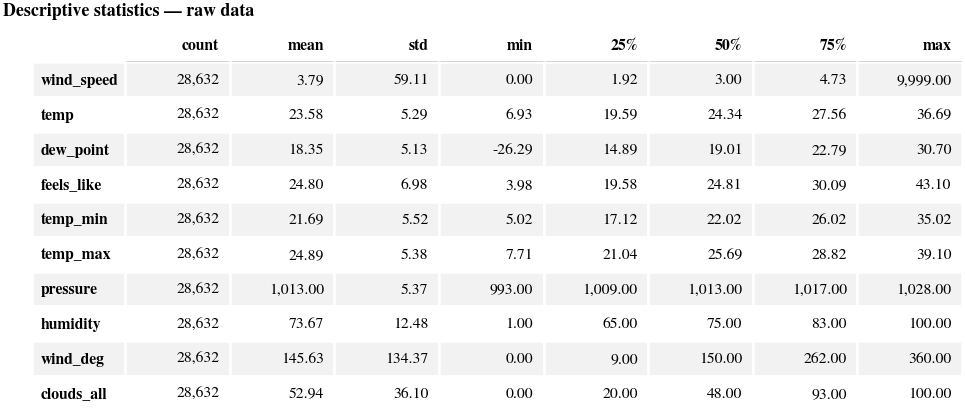

table saved -> results/figures/tables/tab01_descriptive_statistics_raw.png | .pdf | .xlsx


In [5]:
from google.colab import drive
drive.mount("/content/drive")

if not os.path.isfile(CSV_PATH):
    folder = os.path.dirname(CSV_PATH)
    isi = sorted(os.listdir(folder)) if os.path.isdir(folder) else "folder tidak ditemukan"
    raise FileNotFoundError(f"File tidak ditemukan: {CSV_PATH}\nIsi folder {folder}: {isi}")

def to_number(s):
    # "2,57" -> 2.57 ; "2.57" -> 2.57 ; spasi dibuang ; teks lain -> NaN
    return pd.to_numeric(s.astype(str).str.strip().str.replace(",", ".", regex=False)
                          .replace({"": np.nan, "nan": np.nan, "None": np.nan}), errors="coerce")

# Semua kolom dibaca sebagai teks dulu agar tidak ada angka yang hilang diam-diam
raw_all = pd.read_csv(CSV_PATH, sep=CSV_SEP, dtype=str, on_bad_lines="warn")
raw_all.columns = raw_all.columns.str.strip()
raw_all[DATETIME_COL] = pd.to_datetime(
    raw_all[DATETIME_COL].str.replace(r"\s*\+\d{4}\s*UTC\s*$", "", regex=True).str.strip(), errors="coerce")
n_bad_time = int(raw_all[DATETIME_COL].isna().sum())
raw_all = raw_all.dropna(subset=[DATETIME_COL])

missing_cols = [c for c in [TARGET_COL] + FEATURE_COLS if c not in raw_all.columns]
assert not missing_cols, f"Kolom tidak ditemukan: {missing_cols}. Kolom tersedia: {list(raw_all.columns)}"

raw = (raw_all.sort_values(DATETIME_COL).drop_duplicates(DATETIME_COL).set_index(DATETIME_COL)
              [[TARGET_COL] + FEATURE_COLS].apply(to_number))

# --- Cek kelengkapan setiap kolom setelah konversi angka ---
miss = raw.isna().mean()
print(f"{len(raw):,} baris | {raw.index.min()} s/d {raw.index.max()} | timestamp tak terbaca: {n_bad_time}")
print("Persentase kosong per kolom:\n" + (miss * 100).round(2).to_string())
if miss[TARGET_COL] > MAX_TARGET_MISSING:
    contoh = raw_all[TARGET_COL].dropna().head(10).tolist()
    raise ValueError(f"{miss[TARGET_COL]*100:.1f}% wind speed kosong (batas {MAX_TARGET_MISSING*100:.0f}%). "
                     f"Contoh nilai mentah: {contoh}. Cek CSV_SEP / format angka.")
dropped = [c for c in FEATURE_COLS if miss[c] > MAX_FEATURE_MISSING]
if dropped:
    print(f"PERINGATAN: kolom {dropped} > {MAX_FEATURE_MISSING*100:.0f}% kosong -> dikeluarkan dari input.")
    FEATURE_COLS = [c for c in FEATURE_COLS if c not in dropped]
USE_COLS = [TARGET_COL] + FEATURE_COLS
raw = raw[USE_COLS]
DESC_RAW = raw.describe().T
display(DESC_RAW.round(2))
save_table_image(DESC_RAW, "tab01_descriptive_statistics_raw", "Descriptive statistics — raw data")

## 4b. Pemeriksaan data (data quality check)
Setiap variabel diperiksa sebelum preprocessing: nilai kosong, duplikat timestamp, jam yang hilang,
nilai di luar batas fisik, outlier IQR (1.5× dan 3×), serta statistik deskriptif. Hasil disimpan ke
`results/data_quality_report.csv` dan divisualisasikan dengan boxplot.

Rentang waktu        : 2020-01-01 00:00:00  s/d  2023-04-07 23:00:00
Jumlah baris         : 28,636  (setelah hapus duplikat: 28,632)
Timestamp duplikat   : 4
Jam yang hilang      : 0 dari 28,632 (0.00%) dalam 0 celah; celah terpanjang = 0 jam


,count,missing,missing_%,non_numeric,min,Q1,median,Q3,max,mean,std,skew,out_of_range,phys_limit,outlier_IQR1.5,outlier_IQR3,constant_run_max_h
variable,,,,,,,,,,,,,,,,,
wind_speed,28632,0,0.0,0,0.00,1.920,3.00,4.730,9999.00,3.795,59.109,168.890,1,"[0, 60]",458,1,3
temp,28632,0,0.0,0,6.93,19.588,24.34,27.562,36.69,23.585,5.294,-0.307,0,"[-20, 50]",7,0,8
dew_point,28632,0,0.0,0,-26.29,14.890,19.01,22.790,30.70,18.351,5.134,-0.784,0,"[-30, 40]",193,3,6
feels_like,28632,0,0.0,0,3.98,19.580,24.81,30.090,43.10,24.803,6.981,0.120,0,"[-30, 60]",0,0,6
temp_min,28632,0,0.0,0,5.02,17.120,22.02,26.020,35.02,21.695,5.518,-0.208,0,"[-20, 50]",0,0,16
temp_max,28632,0,0.0,0,7.71,21.040,25.69,28.820,39.10,24.892,5.375,-0.278,0,"[-20, 50]",29,0,13
pressure,28632,0,0.0,0,993.00,1009.000,1013.00,1017.000,1028.00,1013.001,5.369,-0.150,0,"[900, 1100]",104,0,17
humidity,28632,0,0.0,0,1.00,65.000,75.00,83.000,100.00,73.672,12.481,-0.534,0,"[0, 100]",162,3,14
wind_deg,28632,0,0.0,0,0.00,9.000,150.00,262.000,360.00,145.632,134.372,0.328,0,"[0, 360]",0,0,9


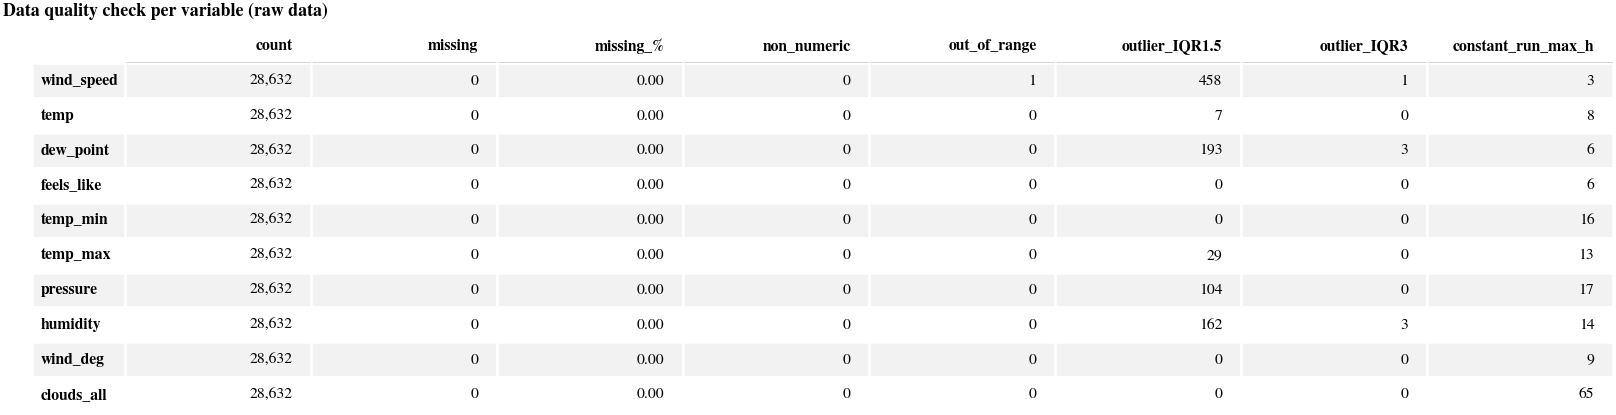

table saved -> results/figures/tables/tab02_data_quality_check.png | .pdf | .xlsx
Baris dengan temp_min > temp_max: 0
Wind speed = 0 (calm): 311 jam


In [6]:
n_dup_ts = int(raw_all[DATETIME_COL].duplicated().sum())
full_idx = pd.date_range(raw.index.min(), raw.index.max(), freq="h")
missing_hours = full_idx.difference(raw.index)
gaps = pd.Series(missing_hours).diff().ne(pd.Timedelta(hours=1)).cumsum()
gap_len = pd.Series(missing_hours).groupby(gaps).size() if len(missing_hours) else pd.Series(dtype=int)

print(f"Rentang waktu        : {raw.index.min()}  s/d  {raw.index.max()}")
print(f"Jumlah baris         : {len(raw_all):,}  (setelah hapus duplikat: {len(raw):,})")
print(f"Timestamp duplikat   : {n_dup_ts}")
print(f"Jam yang hilang      : {len(missing_hours):,} dari {len(full_idx):,} "
      f"({len(missing_hours)/len(full_idx)*100:.2f}%) dalam {len(gap_len)} celah; "
      f"celah terpanjang = {int(gap_len.max()) if len(gap_len) else 0} jam")

rows = []
for c in USE_COLS:
    x = raw[c]; xv = x.dropna()
    q1, q3 = xv.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = PHYSICAL_LIMITS.get(c, (-np.inf, np.inf))
    rows.append({
        "variable": c, "count": int(xv.size), "missing": int(x.isna().sum()),
        "missing_%": x.isna().mean() * 100,
        "non_numeric": int(raw_all[c].notna().sum() - to_number(raw_all[c]).notna().sum()),
        "min": xv.min(), "Q1": q1, "median": xv.median(), "Q3": q3, "max": xv.max(),
        "mean": xv.mean(), "std": xv.std(), "skew": xv.skew(),
        "out_of_range": int(((xv < lo) | (xv > hi)).sum()), "phys_limit": f"[{lo}, {hi}]",
        "outlier_IQR1.5": int(((xv < q1 - 1.5*iqr) | (xv > q3 + 1.5*iqr)).sum()),
        "outlier_IQR3": int(((xv < q1 - 3*iqr) | (xv > q3 + 3*iqr)).sum()),
        "constant_run_max_h": int(xv.groupby((xv != xv.shift()).cumsum()).size().max()),
    })
dq = pd.DataFrame(rows).set_index("variable")
dq.to_csv(f"{OUT_DIR}/data_quality_report.csv")
display(dq.round(3))
save_table_image(dq[["count", "missing", "missing_%", "non_numeric", "out_of_range",
                     "outlier_IQR1.5", "outlier_IQR3", "constant_run_max_h"]],
                 "tab02_data_quality_check", "Data quality check per variable (raw data)")

if {"temp_min", "temp_max"} <= set(raw.columns):
    print("Baris dengan temp_min > temp_max:", int((raw.temp_min > raw.temp_max).sum()))
if (raw[TARGET_COL] == 0).any():
    print(f"Wind speed = 0 (calm): {int((raw[TARGET_COL] == 0).sum())} jam")

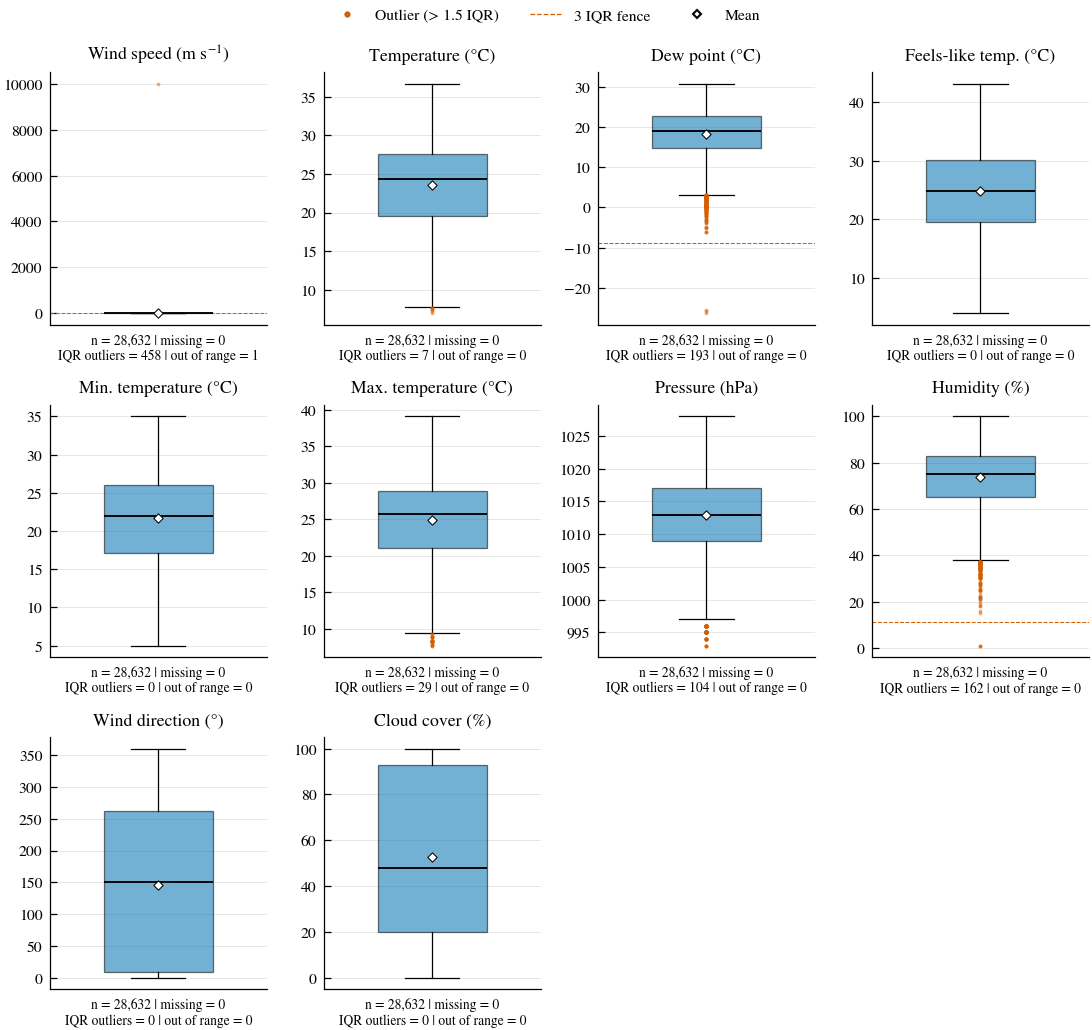

saved -> results/figures/fig00a_raw_boxplots_per_variable.png | .pdf | .tiff


In [7]:
# Fig 0a: boxplot setiap variabel (data mentah) + pagar IQR & batas fisik
ncol = 4; nrow = int(np.ceil(len(USE_COLS) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(COL2, 2.2 * nrow + 0.2))
for ax, c in zip(axes.ravel(), USE_COLS):
    xv = raw[c].dropna()
    q1, q3 = xv.quantile([.25, .75]); iqr = q3 - q1
    bp = ax.boxplot(xv, widths=.5, whis=1.5, patch_artist=True,
                    medianprops=dict(color="black", lw=.9), boxprops=dict(lw=.6),
                    whiskerprops=dict(lw=.6), capprops=dict(lw=.6),
                    flierprops=dict(marker="o", ms=1.8, mfc="#D55E00", mec="none", alpha=.5))
    bp["boxes"][0].set_facecolor("#0072B2"); bp["boxes"][0].set_alpha(.55)
    ax.scatter([1], [xv.mean()], marker="D", s=10, color="white", ec="black", lw=.5, zorder=3)
    for f, lsty in [(q1 - 3*iqr, "--"), (q3 + 3*iqr, "--")]:
        if xv.min() <= f <= xv.max(): ax.axhline(f, color="#D55E00", lw=.5, ls=lsty)
    ax.set_xticks([]); ax.set_title(LABELS.get(c, c))
    r = dq.loc[c]
    ax.set_xlabel(f"n = {int(r['count']):,} | missing = {int(r['missing'])}\n"
                  f"IQR outliers = {int(r['outlier_IQR1.5'])} | out of range = {int(r['out_of_range'])}",
                  fontsize=6.5)
for ax in axes.ravel()[len(USE_COLS):]: ax.axis("off")
handles = [Line2D([], [], marker="o", ls="", mfc="#D55E00", mec="none", ms=3, label="Outlier (> 1.5 IQR)"),
           Line2D([], [], color="#D55E00", lw=.6, ls="--", label="3 IQR fence"),
           Line2D([], [], marker="D", ls="", mfc="white", mec="black", ms=3, label="Mean")]
fig.legend(handles=handles, ncol=3, loc="upper center", bbox_to_anchor=(.5, 1.03))
fig.tight_layout(); save_fig(fig, "fig00a_raw_boxplots_per_variable")

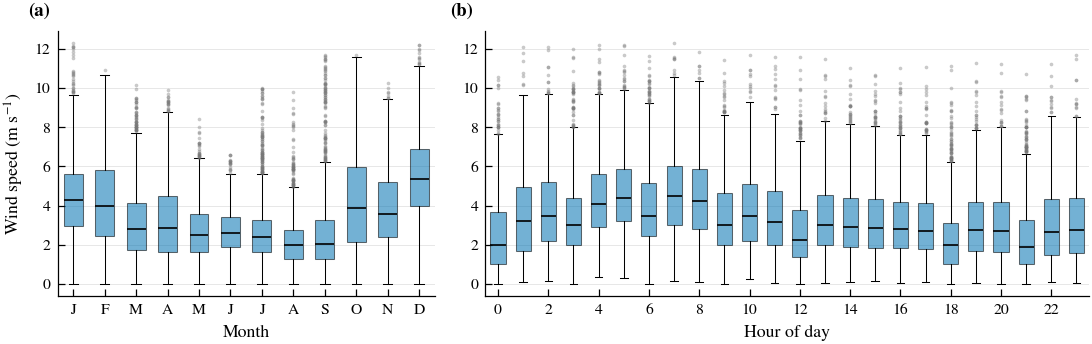

saved -> results/figures/fig00b_wind_speed_monthly_hourly_boxplots.png | .pdf | .tiff


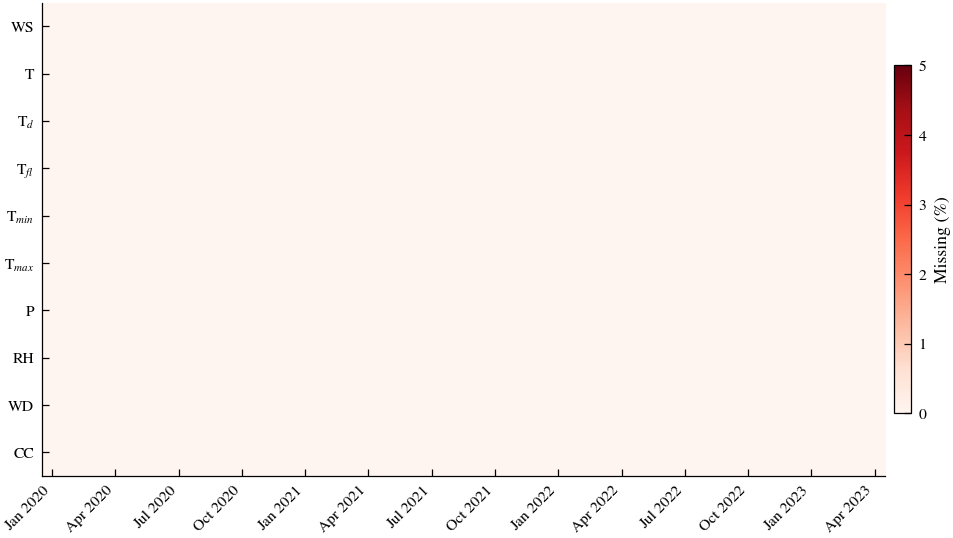

saved -> results/figures/fig00c_missing_data_map.png | .pdf | .tiff


In [8]:
# Fig 0b: boxplot wind speed per bulan dan per jam (pola musiman & diurnal)
ws = raw[TARGET_COL].where(raw[TARGET_COL].between(*PHYSICAL_LIMITS.get(TARGET_COL, (-np.inf, np.inf))))
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.5), gridspec_kw=dict(width_ratios=[1, 1.6]))
kw = dict(widths=.6, patch_artist=True, medianprops=dict(color="black", lw=.8),
          boxprops=dict(lw=.5, facecolor="#0072B2", alpha=.55), whiskerprops=dict(lw=.5),
          capprops=dict(lw=.5), flierprops=dict(marker=".", ms=1.5, mec="#777", alpha=.4))
axes[0].boxplot([ws[ws.index.month == m].dropna() for m in range(1, 13)], **kw)
axes[0].set_xticks(range(1, 13)); axes[0].set_xticklabels(["J","F","M","A","M","J","J","A","S","O","N","D"])
axes[0].set_xlabel("Month"); axes[0].set_ylabel(LABELS[TARGET_COL])
axes[1].boxplot([ws[ws.index.hour == h].dropna() for h in range(24)], **kw)
axes[1].set_xticks(range(1, 25, 2)); axes[1].set_xticklabels(range(0, 24, 2)); axes[1].set_xlabel("Hour of day")
for ax, l in zip(axes, "ab"): ax.grid(axis="x", visible=False); panel_label(ax, l)
fig.tight_layout(); save_fig(fig, "fig00b_wind_speed_monthly_hourly_boxplots")

# Fig 0c: peta data hilang per bulan per variabel
miss = raw.reindex(full_idx).isna().resample("MS").mean() * 100
fig, ax = plt.subplots(figsize=(COL2, 0.32 * len(USE_COLS) + 0.9))
im = ax.imshow(miss.T.values, aspect="auto", cmap="Reds", vmin=0, vmax=max(5, miss.values.max()),
               interpolation="nearest")
ax.set_yticks(range(len(USE_COLS))); ax.set_yticklabels([SHORT.get(c, c) for c in USE_COLS])
step = max(1, len(miss) // 12)
ax.set_xticks(range(0, len(miss), step)); ax.set_xticklabels(miss.index[::step].strftime("%b %Y"), rotation=45, ha="right")
ax.grid(False); cb = fig.colorbar(im, ax=ax, fraction=.02, pad=.01); cb.set_label("Missing (%)")
save_fig(fig, "fig00c_missing_data_map")

## 5. Preprocessing (anomali, celah waktu, interpolasi)

Slot per jam: 28,632 | target kosong sebelum interpolasi: 1
Sisa NaN setelah interpolasi (dibuang di windowing): 0
Input LSTM: ['temp', 'dew_point', 'feels_like', 'temp_min', 'temp_max', 'pressure', 'humidity', 'wind_deg', 'clouds_all'] -> shape (168, 9)


,wind_speed,temp,dew_point,feels_like,temp_min,temp_max,pressure,humidity,wind_deg,clouds_all,temp_min>temp_max
anomalies_flagged,1,0,3,0,0,0,0,3,0,0,0


,missing_after,min,max,out_of_range_after
wind_speed,0,0.00,12.33,0
temp,0,6.93,36.69,0
dew_point,0,-6.04,30.70,0
feels_like,0,3.98,43.10,0
temp_min,0,5.02,35.02,0
temp_max,0,7.71,39.10,0
pressure,0,993.00,1028.00,0
humidity,0,15.00,100.00,0
wind_deg,0,0.00,360.00,0
clouds_all,0,0.00,100.00,0


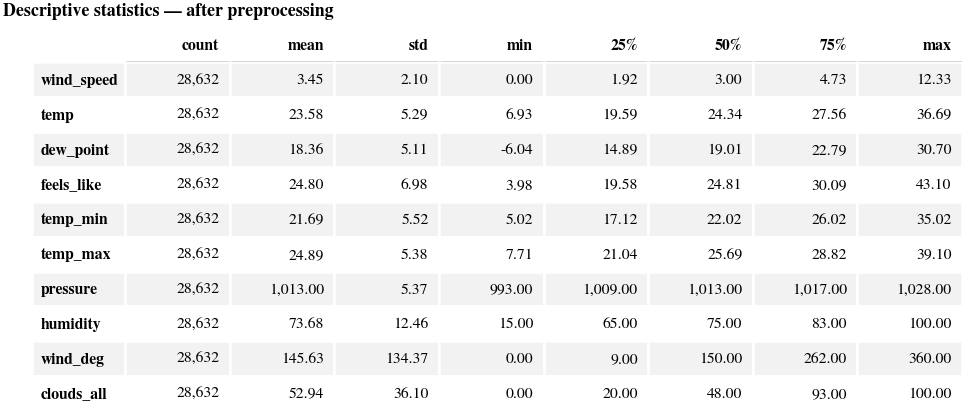

table saved -> results/figures/tables/tab03_descriptive_statistics_clean.png | .pdf | .xlsx


,Raw rows,Valid (raw),Missing (raw),Anomalies removed,Interpolated,Valid (final),Remaining missing
Variable,,,,,,,
wind_speed,28636,28632,0,1,1,28632,0
temp,28636,28632,0,0,0,28632,0
dew_point,28636,28632,0,3,3,28632,0
feels_like,28636,28632,0,0,0,28632,0
temp_min,28636,28632,0,0,0,28632,0
temp_max,28636,28632,0,0,0,28632,0
pressure,28636,28632,0,0,0,28632,0
humidity,28636,28632,0,3,3,28632,0
wind_deg,28636,28632,0,0,0,28632,0


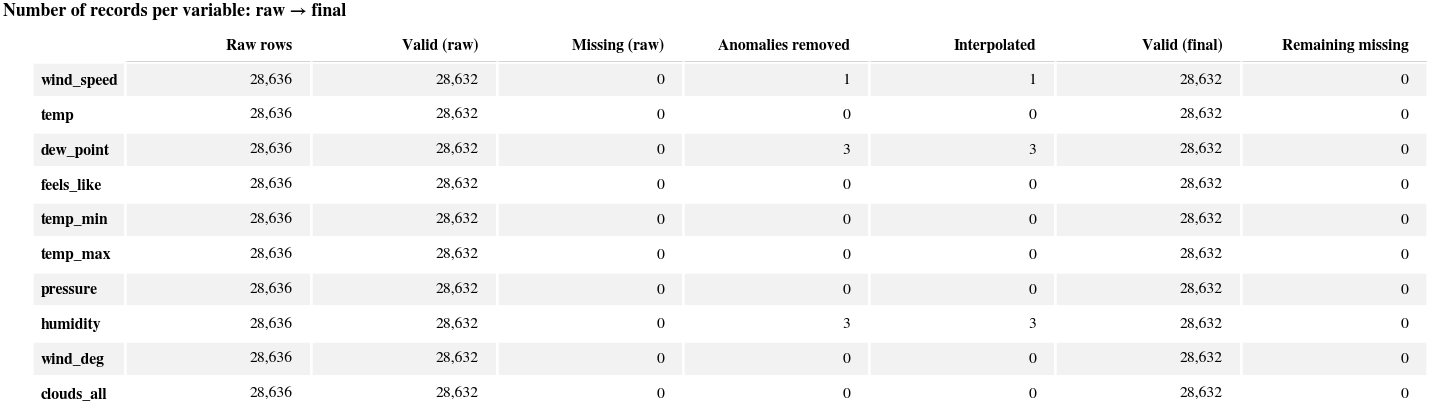

table saved -> results/figures/tables/tab04_data_count_per_variable.png | .pdf | .xlsx


In [9]:
df = raw.asfreq("h")                      # deret per jam kontinu
anomaly = {}
for col in df.columns:
    bad = pd.Series(False, index=df.index)
    if col in PHYSICAL_LIMITS:
        lo, hi = PHYSICAL_LIMITS[col]
        bad |= (df[col] < lo) | (df[col] > hi)
    if col != "wind_deg":                 # arah angin sirkular -> tanpa IQR
        q1, q3 = df[col].quantile([.25, .75]); iqr = q3 - q1
        bad |= (df[col] < q1 - IQR_K * iqr) | (df[col] > q3 + IQR_K * iqr)
    anomaly[col] = int(bad.sum())
    df.loc[bad, col] = np.nan
if {"temp_min", "temp_max"} <= set(df.columns):
    swap = df.temp_min > df.temp_max
    df.loc[swap, ["temp_min", "temp_max"]] = np.nan
    anomaly["temp_min>temp_max"] = int(swap.sum())

n_missing_slots = int(df[TARGET_COL].isna().sum())
df_before_interp = df.copy()                      # untuk menghitung jumlah data yang diinterpolasi
target_is_real = df[TARGET_COL].notna()          # True = observasi asli (bukan hasil interpolasi)
# Interpolasi hanya untuk celah pendek; TIDAK ada ffill/bfill (agar data uji tidak menjadi konstan)
df = df.interpolate(method="time", limit=MAX_INTERP_GAP, limit_area="inside")

if WIND_DEG_SINCOS and "wind_deg" in df.columns:
    r = np.deg2rad(df.pop("wind_deg"))
    df["wind_deg_sin"], df["wind_deg_cos"] = np.sin(r), np.cos(r)

INPUT_COLS = ([TARGET_COL] if USE_TARGET_HISTORY else []) + [c for c in df.columns if c != TARGET_COL]
prep_report = pd.DataFrame({"anomalies_flagged": anomaly})
prep_report.to_csv(f"{OUT_DIR}/preprocessing_report.csv")
print(f"Slot per jam: {len(df):,} | target kosong sebelum interpolasi: {n_missing_slots}")
print(f"Sisa NaN setelah interpolasi (dibuang di windowing): {int(df.isna().any(axis=1).sum())}")
print("Input LSTM:", INPUT_COLS, f"-> shape ({WINDOW}, {len(INPUT_COLS)})")
display(prep_report.T)

# Cek ulang setelah preprocessing
post = pd.DataFrame({
    "missing_after": df.isna().sum(),
    "min": df.min(), "max": df.max(),
    "out_of_range_after": pd.Series({c: int(((df[c] < PHYSICAL_LIMITS[c][0]) | (df[c] > PHYSICAL_LIMITS[c][1])).sum())
                                     for c in df.columns if c in PHYSICAL_LIMITS}),
})
post.to_csv(f"{OUT_DIR}/data_check_after_preprocessing.csv")
display(post.round(3))

# --- Tabel: statistik setelah preprocessing & jumlah data per variabel (awal -> akhir) ---
DESC_CLEAN = df.describe().T
save_table_image(DESC_CLEAN, "tab03_descriptive_statistics_clean", "Descriptive statistics — after preprocessing")
cnt = pd.DataFrame(index=[c for c in raw.columns if c in df_before_interp.columns])
cnt["Raw rows"]              = len(raw_all)
cnt["Valid (raw)"]           = raw.reindex(columns=cnt.index).notna().sum()
cnt["Missing (raw)"]         = len(raw) - cnt["Valid (raw)"]
cnt["Anomalies removed"]     = pd.Series(anomaly).reindex(cnt.index).fillna(0).astype(int)
cnt["Interpolated"]          = [int((df_before_interp[c].isna() & df[c].notna()).sum()) if c in df else 0 for c in cnt.index]
cnt["Valid (final)"]         = [int(df[c].notna().sum()) if c in df else 0 for c in cnt.index]
cnt["Remaining missing"]     = [int(df[c].isna().sum()) if c in df else 0 for c in cnt.index]
cnt.index.name = "Variable"
display(cnt)
save_table_image(cnt, "tab04_data_count_per_variable", "Number of records per variable: raw → final")
assert post["out_of_range_after"].fillna(0).sum() == 0, "Masih ada nilai di luar batas fisik!"

### Gambar: distribusi sebelum vs sesudah preprocessing & korelasi variabel

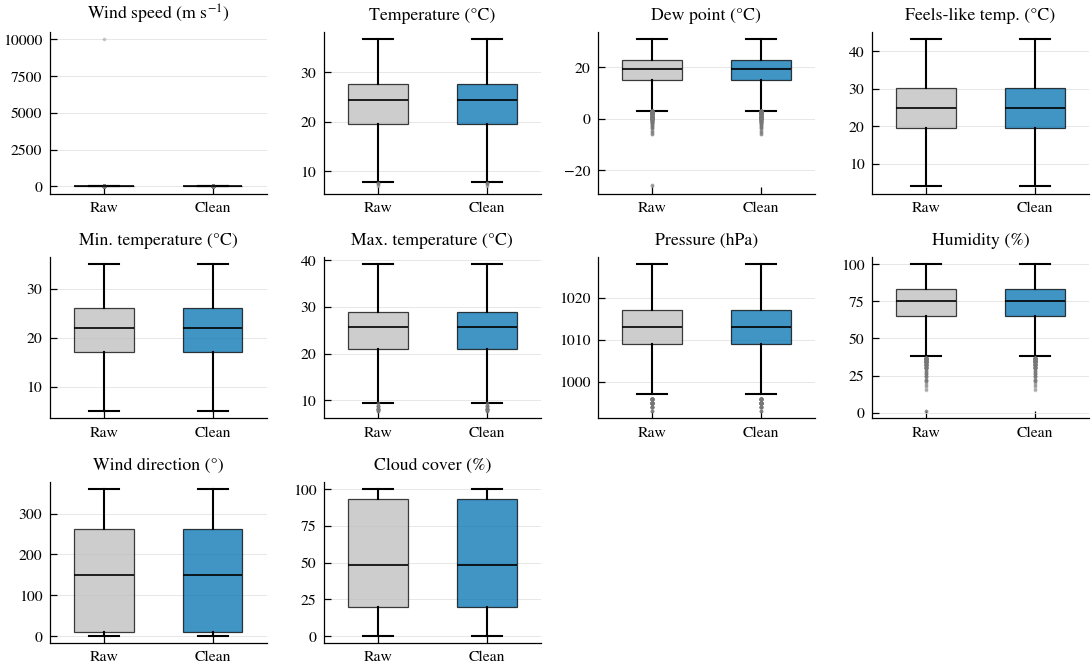

saved -> results/figures/fig01_preprocessing_boxplots.png | .pdf | .tiff


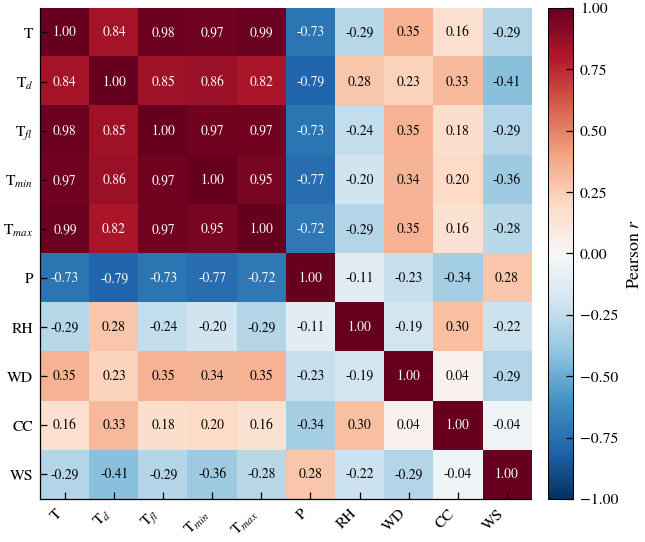

saved -> results/figures/fig02_correlation_matrix.png | .pdf | .tiff


In [10]:
cols = list(raw.columns)
ncol = 4; nrow = int(np.ceil(len(cols) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(COL2, 1.45 * nrow + 0.3))
for ax, c in zip(axes.ravel(), cols):
    b = raw[c].dropna(); a = df[c].dropna() if c in df else None
    bp = ax.boxplot([b] + ([a] if a is not None else []), widths=0.55, showfliers=True,
                    patch_artist=True, medianprops=dict(color="black", lw=0.8),
                    flierprops=dict(marker=".", ms=1.5, alpha=.4, mec="#777"))
    for p, colr in zip(bp["boxes"], ["#bdbdbd", "#0072B2"]):
        p.set_facecolor(colr); p.set_alpha(.75); p.set_linewidth(.6)
    ax.set_xticks([1, 2] if a is not None else [1]); ax.set_xticklabels(["Raw", "Clean"][:len(bp["boxes"])])
    ax.set_title(LABELS.get(c, c)); ax.grid(axis="x", visible=False)
for ax in axes.ravel()[len(cols):]: ax.axis("off")
fig.tight_layout()
save_fig(fig, "fig01_preprocessing_boxplots")

CORR_COLS = [c for c in df.columns if c != TARGET_COL] + [TARGET_COL]   # wind speed selalu ditampilkan
corr = df[CORR_COLS].corr()
fig, ax = plt.subplots(figsize=(COL1 * 1.35, COL1 * 1.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ticks = [SHORT.get(c, c) for c in corr.columns]
ax.set_xticks(range(len(ticks))); ax.set_xticklabels(ticks, rotation=45, ha="right")
ax.set_yticks(range(len(ticks))); ax.set_yticklabels(ticks); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(v) > .6 else "black")
cb = fig.colorbar(im, ax=ax, fraction=.046, pad=.03); cb.set_label("Pearson $r$"); cb.outline.set_linewidth(.5)
save_fig(fig, "fig02_correlation_matrix")

## 6. Split data (80% train / 20% validation + 1 minggu held-out test)

,samples,start,end
train,22603,2020-01-08 00:00:00,2022-08-06 18:00:00
val,5693,2022-08-06 19:00:00,2023-03-31 23:00:00
test,168,2023-04-01 00:00:00,2023-04-07 23:00:00


Shape input LSTM: (168, 9)
Minggu uji: 168/168 jam | observasi asli = 100.0% | wind speed 0.31–5.19 m/s (std 1.253)


,Records,% of raw
Stage,,
Raw rows in CSV,28636,100.000000
Valid timestamps,28636,100.000000
After removing duplicates,28632,99.986032
Hourly slots (continuous),28632,99.986032
Complete rows before interpolation,28628,99.972063
Complete rows after preprocessing,28632,99.986032
Sequences (168 h window),28464,99.399357
Training set,22603,78.932113
Validation set,5693,19.880570


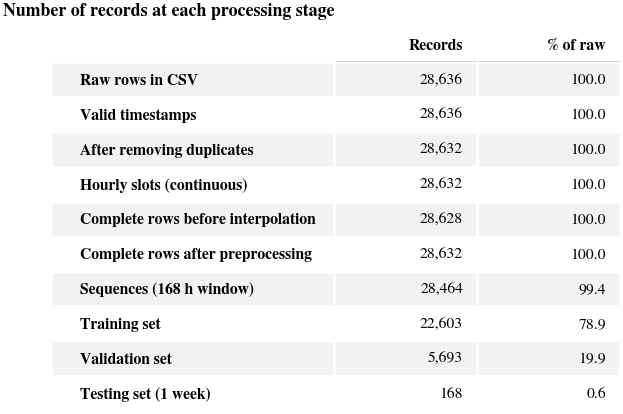

table saved -> results/figures/tables/tab05_data_flow_counts.png | .pdf | .xlsx


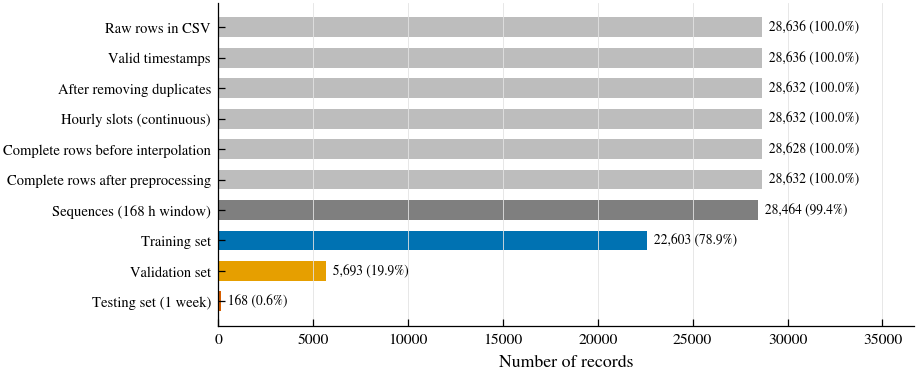

saved -> results/figures/fig00d_data_flow_counts.png | .pdf | .tiff


In [11]:
test_start = pd.Timestamp(TEST_START)
test_end   = pd.Timestamp(TEST_END) + pd.Timedelta(hours=23)
dev        = df.loc[:test_start - pd.Timedelta(hours=1)]
train_end  = dev.index[int(len(dev) * TRAIN_RATIO) - 1]

# Scaler di-fit hanya pada data train (tanpa kebocoran informasi)
x_scaler = MinMaxScaler().fit(df.loc[:train_end, INPUT_COLS].dropna())
y_scaler = MinMaxScaler().fit(df.loc[:train_end, [TARGET_COL]].dropna())
Xs = x_scaler.transform(df[INPUT_COLS]).astype("float32")
ys = y_scaler.transform(df[[TARGET_COL]]).ravel().astype("float32")

# Sliding window: 168 jam terakhir -> wind speed jam ke-(t+HORIZON)
from numpy.lib.stride_tricks import sliding_window_view
win = sliding_window_view(Xs, (WINDOW, Xs.shape[1]))[:, 0]          # (N-WINDOW+1, WINDOW, F)
win = win[: len(df) - WINDOW - HORIZON + 1]
tgt_idx = np.arange(WINDOW + HORIZON - 1, len(df))
y_win, t_win = ys[tgt_idx], df.index[tgt_idx]
ok = ~np.isnan(win).any(axis=(1, 2)) & ~np.isnan(y_win)
X_all, y_all, t_all = win[ok], y_win[ok], t_win[ok]

m_tr = t_all <= train_end
m_va = (t_all > train_end) & (t_all < test_start)
m_te = (t_all >= test_start) & (t_all <= test_end)
SETS = {"train": m_tr, "val": m_va, "test": m_te}
X = {k: X_all[m] for k, m in SETS.items()}
Y = {k: y_all[m] for k, m in SETS.items()}
T = {k: t_all[m] for k, m in SETS.items()}
Y_ms = {k: y_scaler.inverse_transform(v.reshape(-1, 1)).ravel() for k, v in Y.items()}  # m/s

split_tbl = pd.DataFrame({k: [len(X[k]), T[k].min(), T[k].max()] for k in SETS},
                         index=["samples", "start", "end"]).T
display(split_tbl)
print("Shape input LSTM:", X["train"].shape[1:])

# --- Validasi data uji (mencegah R2 = 0 karena target konstan / hasil isian) ---
n_expected = int((test_end - test_start) / pd.Timedelta(hours=1)) + 1
real_frac = target_is_real.reindex(T["test"]).mean() if len(T["test"]) else 0
print(f"Minggu uji: {len(T['test'])}/{n_expected} jam | observasi asli = {real_frac*100:.1f}% | "
      f"wind speed {Y_ms['test'].min():.2f}–{Y_ms['test'].max():.2f} m/s (std {Y_ms['test'].std():.3f})")
assert len(T["test"]) >= 0.9 * n_expected, "Data minggu uji tidak lengkap. Cek TEST_START/TEST_END & data mentah."
assert Y_ms["test"].std() > 1e-3, "Wind speed minggu uji konstan -> R2 tidak bermakna. Cek pembacaan data."
assert real_frac >= MIN_TEST_REAL_OBS, (f"Hanya {real_frac*100:.1f}% target minggu uji berupa data asli; "
                                        "sisanya hasil interpolasi. Pilih minggu uji lain atau perbaiki data.")

# --- Jumlah data dari awal sampai akhir (tabel + gambar) ---
FLOW = pd.DataFrame({"Records": [
    len(raw_all) + n_bad_time, len(raw_all), len(raw), len(df),
    int(df_before_interp.notna().all(axis=1).sum()), int(df.notna().all(axis=1).sum()),
    len(X_all), len(X["train"]), len(X["val"]), len(X["test"])]},
    index=["Raw rows in CSV", "Valid timestamps", "After removing duplicates", "Hourly slots (continuous)",
           "Complete rows before interpolation", "Complete rows after preprocessing",
           f"Sequences ({WINDOW} h window)", "Training set", "Validation set", "Testing set (1 week)"])
FLOW["% of raw"] = FLOW["Records"] / FLOW["Records"].iloc[0] * 100
FLOW.index.name = "Stage"
display(FLOW)
save_table_image(FLOW, "tab05_data_flow_counts", "Number of records at each processing stage", decimals=1)

fig, ax = plt.subplots(figsize=(COL2 * .8, 2.8))
colors = ["#bdbdbd"] * 6 + ["#7f7f7f", "#0072B2", "#E69F00", "#D55E00"]
yy = np.arange(len(FLOW))[::-1]
bars = ax.barh(yy, FLOW["Records"], color=colors, height=.65)
for b, v, p in zip(bars, FLOW["Records"], FLOW["% of raw"]):
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f"  {v:,} ({p:.1f}%)", va="center", fontsize=6.5)
ax.set_yticks(yy); ax.set_yticklabels(FLOW.index, fontsize=7)
ax.set_xlabel("Number of records"); ax.set_xlim(0, FLOW["Records"].max() * 1.28); ax.grid(axis="y", visible=False)
save_fig(fig, "fig00d_data_flow_counts")

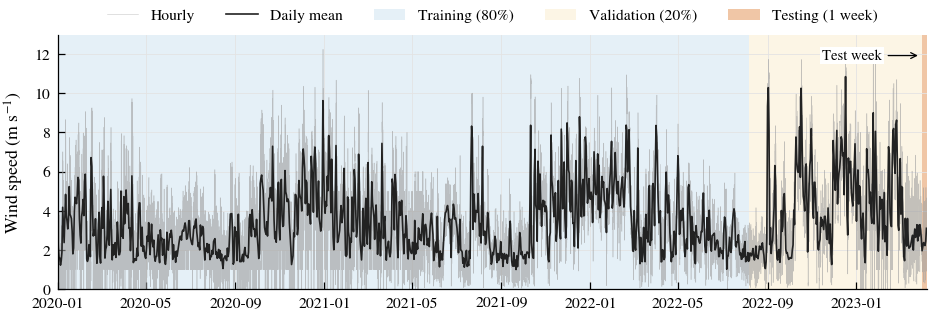

saved -> results/figures/fig03_wind_speed_series_split.png | .pdf | .tiff


In [12]:
fig, ax = plt.subplots(figsize=(COL2, 2.2))
daily = df[TARGET_COL].resample("D").mean()
ax.plot(df.index, df[TARGET_COL], color="#9e9e9e", lw=.25, alpha=.6, label="Hourly")
ax.plot(daily.index, daily, color=OBS_COLOR, lw=.8, label="Daily mean")
spans = [(df.index.min(), train_end, "#0072B2", "Training (80%)"),
         (train_end, test_start, "#E69F00", "Validation (20%)"),
         (test_start, test_end, "#D55E00", "Testing (1 week)")]
for a, b, c, l in spans:
    ax.axvspan(a, b, color=c, alpha=.35 if "Testing" in l else .10, lw=0, label=l)
ax.set_ylabel(LABELS[TARGET_COL]); ax.set_xlim(df.index.min(), df.index.max()); ax.set_ylim(bottom=0)
ax.annotate("Test week", xy=(test_start, ax.get_ylim()[1] * .92), xytext=(-48, 0), textcoords="offset points",
            fontsize=7, va="center", arrowprops=dict(arrowstyle="->", lw=.6, color="black"),
            bbox=dict(fc="white", ec="none", pad=1))
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(.5, 1.16))
save_fig(fig, "fig03_wind_speed_series_split")

## 7. Stage 1 — LSTM (Input 168×n → LSTM 128 → Dropout 20% → Dense 64 → output)

In [13]:
def build_lstm(n_steps, n_feat):
    inp = layers.Input(shape=(n_steps, n_feat), name="input_layer")
    x = layers.LSTM(LSTM_UNITS, name="lstm_layer")(inp)
    x = layers.Dropout(DROPOUT, name="dropout_layer")(x)
    feat = layers.Dense(DENSE_UNITS, activation="relu", name="lstm_features")(x)  # Output LSTM (64)
    out = layers.Dense(1, name="forecast")(feat)          # head hanya untuk melatih ekstraktor
    m = models.Model(inp, out, name="LSTM_feature_extractor_training")
    m.compile(optimizer=tf.keras.optimizers.Adam(LR), loss="mse",
              metrics=[tf.keras.metrics.RootMeanSquaredError(name="rmse")])
    return m

lstm = build_lstm(WINDOW, len(INPUT_COLS))
lstm.summary()
with open(f"{LOG_DIR}/lstm_model_summary.txt", "w") as f:
    lstm.summary(print_fn=lambda line, *a, **k: f.write(line + "\n"))

cbs = [callbacks.CSVLogger(f"{LOG_DIR}/lstm_epoch_log.csv"),
       callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
       callbacks.ReduceLROnPlateau(monitor="val_loss", factor=.5, patience=5, min_lr=1e-5),
       callbacks.ModelCheckpoint(f"{OUT_DIR}/lstm_best.keras", monitor="val_loss", save_best_only=True)]
_t0 = time.time()
hist = lstm.fit(X["train"], Y["train"], validation_data=(X["val"], Y["val"]),
                epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=cbs, verbose=2)
TIMING["lstm_training_s"] = round(time.time() - _t0, 1)
TIMING["lstm_epochs_run"] = len(hist.history["loss"])
TIMING["lstm_best_epoch"] = int(np.argmin(hist.history["val_loss"])) + 1
print(f"LSTM training: {TIMING['lstm_training_s']} s, {TIMING['lstm_epochs_run']} epoch, "
      f"best epoch = {TIMING['lstm_best_epoch']}")
pd.DataFrame(hist.history).to_csv(f"{OUT_DIR}/lstm_training_history.csv", index_label="epoch")

Model: "LSTM_feature_extractor_training"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 168, 9)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_layer (LSTM)               │ (None, 128)            │        70,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_layer (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_features (Dense)           │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ forecast (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78,977 (308.50 KB)

 Trainable params: 78,977 (308.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
354/354 - 11s - 30ms/step - loss: 0.0178 - rmse: 0.1334 - val_loss: 0.0203 - val_rmse: 0.1425 - learning_rate: 0.0010
Epoch 2/100
354/354 - 5s - 13ms/step - loss: 0.0146 - rmse: 0.1207 - val_loss: 0.0191 - val_rmse: 0.1383 - learning_rate: 0.0010
Epoch 3/100
354/354 - 4s - 13ms/step - loss: 0.0139 - rmse: 0.1179 - val_loss: 0.0196 - val_rmse: 0.1400 - learning_rate: 0.0010
Epoch 4/100
354/354 - 5s - 14ms/step - loss: 0.0134 - rmse: 0.1156 - val_loss: 0.0190 - val_rmse: 0.1377 - learning_rate: 0.0010
Epoch 5/100
354/354 - 4s - 11ms/step - loss: 0.0131 - rmse: 0.1144 - val_loss: 0.0197 - val_rmse: 0.1404 - learning_rate: 0.0010
Epoch 6/100
354/354 - 4s - 12ms/step - loss: 0.0127 - rmse: 0.1129 - val_loss: 0.0188 - val_rmse: 0.1372 - learning_rate: 0.0010
Epoch 7/100
354/354 - 5s - 13ms/step - loss: 0.0125 - rmse: 0.1117 - val_loss: 0.0188 - val_rmse: 0.1373 - learning_rate: 0.0010
Epoch 8/100
354/354 - 4s - 12ms/step - loss: 0.0123 - rmse: 0.1108 - val_loss: 0.0178 - val_rmse

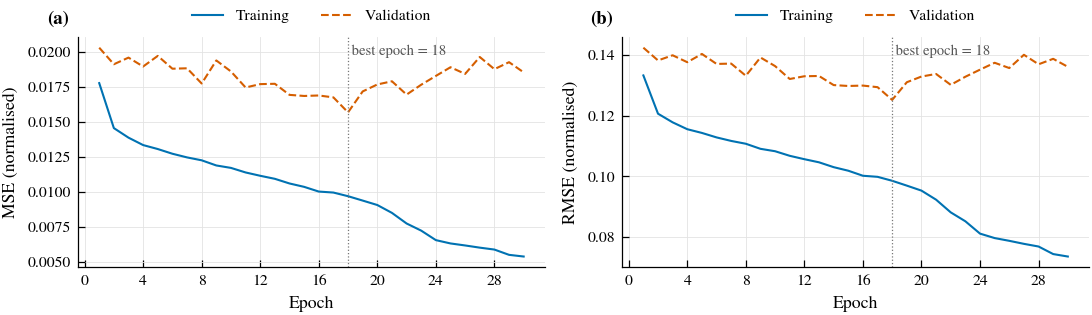

saved -> results/figures/fig04_lstm_learning_curves.png | .pdf | .tiff


In [14]:
h = pd.DataFrame(hist.history); ep = np.arange(1, len(h) + 1)
best_ep = int(h.val_loss.idxmin()) + 1
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.3))
for ax, key, lab in [(axes[0], "loss", "MSE (normalised)"), (axes[1], "rmse", "RMSE (normalised)")]:
    ax.plot(ep, h[key], color="#0072B2", ls="-", label="Training")
    ax.plot(ep, h[f"val_{key}"], color="#D55E00", ls="--", label="Validation")
    ax.axvline(best_ep, color="#777", lw=.6, ls=":")
    ax.text(best_ep, .97, f" best epoch = {best_ep}", transform=ax.get_xaxis_transform(),
            fontsize=7, color="#555", ha="left", va="top")
    ax.set_xlabel("Epoch"); ax.set_ylabel(lab)
    ax.legend(loc="lower center", bbox_to_anchor=(.5, 1.0), ncol=2)
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
panel_label(axes[0], "a"); panel_label(axes[1], "b")
fig.tight_layout(); save_fig(fig, "fig04_lstm_learning_curves")

## 8. Ekstraksi fitur LSTM
Model dipotong pada layer `lstm_features` (Dense 64). Setiap jendela 168×n diubah menjadi **vektor fitur temporal 64 dimensi**,
disimpan ke CSV, lalu menjadi input Stage 2.

In [15]:
extractor = models.Model(lstm.input, lstm.get_layer("lstm_features").output, name="LSTM_feature_extractor")
FEAT = {k: extractor.predict(X[k], batch_size=512, verbose=0) for k in SETS}
FEAT_COLS = [f"f{i+1:02d}" for i in range(DENSE_UNITS)]

for k in SETS:
    out = pd.DataFrame(FEAT[k], columns=FEAT_COLS, index=T[k]); out.index.name = "datetime"
    out[TARGET_COL] = Y_ms[k]
    out.to_csv(f"{OUT_DIR}/lstm_features_{k}.csv")
    print(f"{k:5s}: {FEAT[k].shape} -> {OUT_DIR}/lstm_features_{k}.csv")

dead = (FEAT["train"].std(axis=0) < 1e-6).sum()
print(f"Neuron fitur tidak aktif (selalu 0 karena ReLU): {dead}/{DENSE_UNITS}")

# Standardisasi fitur (fit pada train) untuk regresor
feat_scaler = StandardScaler().fit(FEAT["train"])
F = {k: feat_scaler.transform(v) for k, v in FEAT.items()}

train: (22603, 64) -> results/lstm_features_train.csv
val  : (5693, 64) -> results/lstm_features_val.csv
test : (168, 64) -> results/lstm_features_test.csv
Neuron fitur tidak aktif (selalu 0 karena ReLU): 3/64


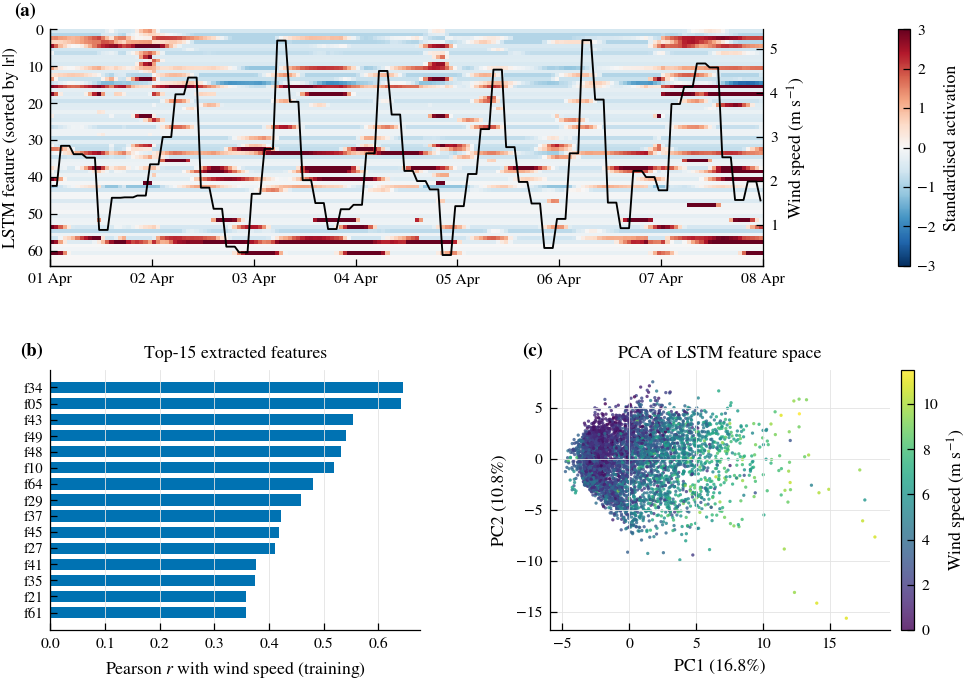

saved -> results/figures/fig05_lstm_feature_extraction.png | .pdf | .tiff


In [16]:
# (a) Peta panas fitur pada minggu uji, (b) korelasi fitur vs wind speed, (c) PCA fitur
r_feat = np.array([np.corrcoef(FEAT["train"][:, i], Y_ms["train"])[0, 1]
                   if FEAT["train"][:, i].std() > 0 else 0 for i in range(DENSE_UNITS)])
order = np.argsort(-np.abs(r_feat))

fig = plt.figure(figsize=(COL2, 5.2))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1], hspace=.42, wspace=.35)

ax = fig.add_subplot(gs[0, :])
Zt = F["test"][:, order].T
im = ax.imshow(Zt, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, interpolation="nearest",
               extent=[0, len(T["test"]), DENSE_UNITS, 0])
ax2 = ax.twinx(); ax2.plot(np.arange(len(T["test"])) + .5, Y_ms["test"], color="black", lw=.9)
ax2.set_ylabel(LABELS[TARGET_COL]); ax2.spines["right"].set_visible(True); ax2.grid(False)
ax.set_ylabel("LSTM feature (sorted by |r|)"); ax.grid(False)
ax.set_xticks(np.arange(0, len(T["test"]) + 1, 24))
ax.set_xticklabels([(T["test"][0] + pd.Timedelta(hours=int(i))).strftime("%d %b") for i in ax.get_xticks()])
cb = fig.colorbar(im, ax=[ax, ax2], fraction=.025, pad=.07); cb.set_label("Standardised activation")
panel_label(ax, "a")

ax = fig.add_subplot(gs[1, 0])
top = order[:15]
ax.barh(range(len(top))[::-1], r_feat[top], color=np.where(r_feat[top] > 0, "#0072B2", "#D55E00"),
        height=.7)
ax.set_yticks(range(len(top))[::-1]); ax.set_yticklabels([FEAT_COLS[i] for i in top], fontsize=7)
ax.axvline(0, color="black", lw=.5); ax.set_xlabel("Pearson $r$ with wind speed (training)")
ax.set_title("Top-15 extracted features"); ax.grid(axis="y", visible=False); panel_label(ax, "b")

ax = fig.add_subplot(gs[1, 1])
pca = PCA(n_components=2, random_state=SEED).fit(F["train"])
P = pca.transform(F["train"]); sub = np.random.default_rng(SEED).choice(len(P), min(5000, len(P)), False)
sc = ax.scatter(P[sub, 0], P[sub, 1], c=Y_ms["train"][sub], cmap="viridis", s=2.5, lw=0, alpha=.8,
                rasterized=True)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
cb = fig.colorbar(sc, ax=ax, fraction=.05, pad=.03); cb.set_label(LABELS[TARGET_COL])
ax.set_title("PCA of LSTM feature space"); panel_label(ax, "c")
save_fig(fig, "fig05_lstm_feature_extraction")

## 9. Stage 2 — Enam regresor pada fitur LSTM

In [17]:
REGRESSORS = {
    "Linear Regression": LinearRegression(),
    "Lasso Regression":  Lasso(alpha=1e-4, max_iter=20000),
    "Ridge Regression":  Ridge(alpha=1.0),
    "SVR":               SVR(kernel="rbf", C=1.0, epsilon=.01, gamma="scale"),
    "Decision Tree":     DecisionTreeRegressor(random_state=SEED),
    "ANN":               MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                                      learning_rate_init=1e-3, max_iter=1000, early_stopping=True,
                                      validation_fraction=.1, n_iter_no_change=20, random_state=SEED),
}

def metrics(y, p):
    mse = mean_squared_error(y, p)
    return dict(RMSE=np.sqrt(mse), MSE=mse, MAE=mean_absolute_error(y, p), R2=r2_score(y, p))

def to_ms(p): return np.clip(y_scaler.inverse_transform(np.asarray(p).reshape(-1, 1)).ravel(), 0, None)

PRED, rows, fitted = {}, [], {}
for name, reg in REGRESSORS.items():
    reg.fit(F["train"], Y["train"]); fitted[name] = reg
    PRED[name] = {k: to_ms(reg.predict(F[k])) for k in SETS}
    for k in SETS:
        rows.append({"Model": f"LSTM–{name}", "Set": k, **metrics(Y_ms[k], PRED[name][k])})

# Baseline (tanpa LSTM): enam regresor yang sama, input = variabel jam terakhir (tanpa jendela 168 jam)
from sklearn.base import clone
XB = {k: X[k][:, -1, :] for k in SETS}
base_scaler = StandardScaler().fit(XB["train"])
XB = {k: base_scaler.transform(v) for k, v in XB.items()}
BPRED, bfitted = {}, {}
for name, reg in REGRESSORS.items():
    rb = clone(reg).fit(XB["train"], Y["train"]); bfitted[name] = rb
    BPRED[name] = {k: to_ms(rb.predict(XB[k])) for k in SETS}
    for k in SETS:
        rows.append({"Model": name, "Set": k, **metrics(Y_ms[k], BPRED[name][k])})

# LSTM standalone (head Dense-1) sebagai pembanding tambahan
lstm_only = {k: to_ms(lstm.predict(X[k], batch_size=512, verbose=0)) for k in SETS}
for k in SETS: rows.append({"Model": "LSTM (standalone)", "Set": k, **metrics(Y_ms[k], lstm_only[k])})
lr_only = BPRED["Linear Regression"]

RES = pd.DataFrame(rows)
RES_IDX = RES.set_index(["Model", "Set"])
RES.to_csv(f"{OUT_DIR}/metrics_all_sets.csv", index=False)

wide = RES.pivot(index="Model", columns="Set", values=["RMSE", "MSE", "MAE", "R2"])
wide = wide.reindex(columns=["train", "val", "test"], level=1)
test_tbl = RES[RES.Set == "test"].set_index("Model").drop(columns="Set")
base = test_tbl.loc["Linear Regression"]          # baseline LR tanpa LSTM
test_tbl["ΔRMSE vs baseline LR (%)"] = (base.RMSE - test_tbl.RMSE) / base.RMSE * 100
test_tbl["ΔMSE vs baseline LR (%)"]  = (base.MSE - test_tbl.MSE) / base.MSE * 100
test_tbl = test_tbl.sort_values("RMSE")
test_tbl.to_csv(f"{OUT_DIR}/metrics_test_summary.csv")
with open(f"{OUT_DIR}/metrics_test_table.tex", "w") as f:
    f.write(test_tbl.round(3).to_latex())

print("=== Held-out test week ==="); display(test_tbl.round(3))
print("=== Semua set ==="); display(wide.round(3))
BEST = [m for m in test_tbl.index if m.startswith("LSTM–")][0].replace("LSTM–", "")
print("Model terbaik:", "LSTM–" + BEST)

=== Held-out test week ===


,RMSE,MSE,MAE,R2,ΔRMSE vs baseline LR (%),ΔMSE vs baseline LR (%)
Model,,,,,,
LSTM (standalone),1.199,1.437,0.893,0.085,16.439,30.176
LSTM–Lasso Regression,1.392,1.939,1.051,-0.235,2.945,5.803
LSTM–Ridge Regression,1.398,1.956,1.055,-0.245,2.521,4.979
LSTM–Linear Regression,1.399,1.956,1.055,-0.246,2.516,4.969
Lasso Regression,1.429,2.043,1.175,-0.301,0.372,0.743
Ridge Regression,1.434,2.058,1.184,-0.310,0.017,0.033
Linear Regression,1.435,2.058,1.184,-0.311,0.000,0.000
ANN,1.444,2.086,1.107,-0.328,-0.662,-1.328
SVR,1.448,2.095,1.100,-0.334,-0.899,-1.805


=== Semua set ===


RMSE                  MSE                  MAE  \
Set                     train    val   test  train    val   test  train   
Model                                                                     
ANN                     1.405  2.004  1.444  1.974  4.014  2.086  1.062   
Decision Tree           0.016  2.558  1.694  0.000  6.544  2.868  0.000   
LSTM (standalone)       1.163  1.532  1.199  1.352  2.347  1.437  0.884   
LSTM–ANN                0.977  1.747  1.660  0.955  3.053  2.757  0.739   
LSTM–Decision Tree      0.000  2.073  1.725  0.000  4.297  2.977  0.000   
LSTM–Lasso Regression   1.123  1.525  1.392  1.261  2.327  1.939  0.849   
LSTM–Linear Regression  1.123  1.526  1.399  1.260  2.328  1.956  0.849   
LSTM–Ridge Regression   1.123  1.526  1.398  1.260  2.328  1.956  0.849   
LSTM–SVR                0.933  1.606  1.706  0.871  2.578  2.909  0.627   
Lasso Regression        1.708  2.153  1.429  2.916  4.636  2.043  1.331   
Linear Regression       1.707  2.152  1.435  2.915  4.633  2.058  1.330   
Ridge Regression        1.707  2.152  1.434  2.915  4.633  2.058  1.330   
SVR                     1.442  1.999  1.448  2.080  3.995  2.095  1.072   

                                         R2                
Set                       val   test  train    val   test  
Model                                                      
ANN                     1.498  1.107  0.493  0.327 -0.328  
Decision Tree           1.907  1.284  1.000 -0.098 -0.826  
LSTM (standalone)       1.143  0.893  0.653  0.606  0.085  
LSTM–ANN                1.246  1.201  0.755  0.488 -0.755  
LSTM–Decision Tree      1.535  1.364  1.000  0.279 -0.896  
LSTM–Lasso Regression   1.130  1.051  0.676  0.610 -0.235  
LSTM–Linear Regression  1.131  1.055  0.676  0.609 -0.246  
LSTM–Ridge Regression   1.131  1.055  0.676  0.609 -0.245  
LSTM–SVR                1.163  1.261  0.776  0.568 -0.852  
Lasso Regression        1.660  1.175  0.251  0.222 -0.301  
Linear Regression       1.659  1.184  0.251  0.223 -0.311  
Ridge Regression        1.659  1.184  0.251  0.223 -0.310  
SVR                     1.496  1.100  0.466  0.330 -0.334

Model terbaik: LSTM–Lasso Regression


## 9b. Tabel hasil pengujian (format paper)
Training RMSE/MSE vs Testing RMSE/MSE untuk model baseline (tanpa LSTM) dan model LSTM-based, beserta keputusan fit.
Kriteria: **Overfit** bila selisih relatif RMSE testing–training > `OVERFIT_GAP`;
**Underfit** bila R² training < `UNDERFIT_R2`; selain itu **Good fit**.

RMSE (Training)  \
Group                          Model                                         
Baseline models (without LSTM) Linear Regression                     1.707   
                               Lasso Regression                      1.708   
                               Ridge Regression                      1.707   
                               Support Vector Regression             1.442   
                               Decision Tree Regression              0.016   
                               Artificial Neural Networks            1.405   
Proposed LSTM-based models     LSTM–LR                               1.123   
                               LSTM–LASSO                            1.123   
                               LSTM–RR                               1.123   
                               LSTM–SVR                              0.933   
                               LSTM–DTR                              0.000   
                               LSTM–ANN                              0.977   

                                                           RMSE (Testing)  \
Group                          Model                                        
Baseline models (without LSTM) Linear Regression                    1.435   
                               Lasso Regression                     1.429   
                               Ridge Regression                     1.434   
                               Support Vector Regression            1.448   
                               Decision Tree Regression             1.694   
                               Artificial Neural Networks           1.444   
Proposed LSTM-based models     LSTM–LR                              1.399   
                               LSTM–LASSO                           1.392   
                               LSTM–RR                              1.398   
                               LSTM–SVR                             1.706   
                               LSTM–DTR                             1.725   
                               LSTM–ANN                             1.660   

                                                           MSE (Training)  \
Group                          Model                                        
Baseline models (without LSTM) Linear Regression                    2.915   
                               Lasso Regression                     2.916   
                               Ridge Regression                     2.915   
                               Support Vector Regression            2.080   
                               Decision Tree Regression             0.000   
                               Artificial Neural Networks           1.974   
Proposed LSTM-based models     LSTM–LR                              1.260   
                               LSTM–LASSO                           1.261   
                               LSTM–RR                              1.260   
                               LSTM–SVR                             0.871   
                               LSTM–DTR                             0.000   
                               LSTM–ANN                             0.955   

                                                           MSE (Testing)  \
Group                          Model                                       
Baseline models (without LSTM) Linear Regression                   2.058   
                               Lasso Regression                    2.043   
                               Ridge Regression                    2.058   
                               Support Vector Regression           2.095   
                               Decision Tree Regression            2.868   
                               Artificial Neural Networks          2.086   
Proposed LSTM-based models     LSTM–LR                             1.956   
                               LSTM–LASSO                          1.939   
                               LSTM–RR          

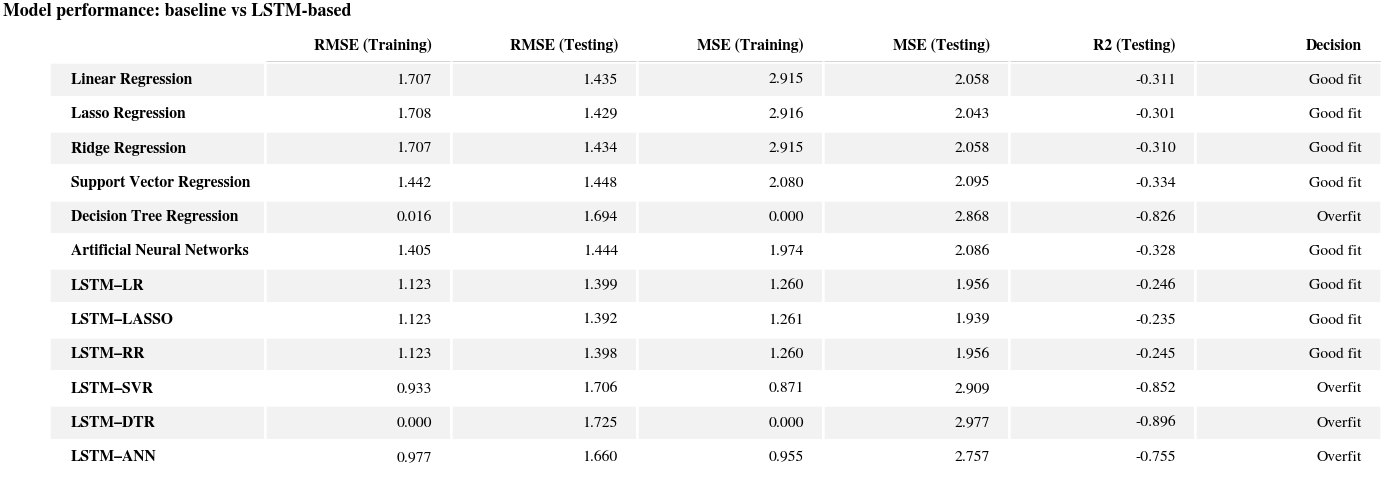

table saved -> results/figures/tables/tab06_model_performance.png | .pdf | .xlsx
LSTM–Lasso Regression: RMSE 1.392 m/s, MSE 1.939 m²/s² | baseline LR: RMSE 1.435, MSE 2.058
Penurunan RMSE = 2.9% | penurunan MSE = 5.8%
Rentang prediksi minggu uji: 0.67–6.08 m/s


In [18]:
ABBR = {"Linear Regression": "LR", "Lasso Regression": "LASSO", "Ridge Regression": "RR",
        "SVR": "SVR", "Decision Tree": "DTR", "ANN": "ANN"}
FULL = {"Linear Regression": "Linear Regression", "Lasso Regression": "Lasso Regression",
        "Ridge Regression": "Ridge Regression", "SVR": "Support Vector Regression",
        "Decision Tree": "Decision Tree Regression", "ANN": "Artificial Neural Networks"}

def decision(tr_rmse, te_rmse, tr_r2):
    if tr_r2 < UNDERFIT_R2: return "Underfit"
    if (te_rmse - tr_rmse) / te_rmse > OVERFIT_GAP: return "Overfit"
    return "Good fit"

paper_rows = []
for group, prefix, label in [("Baseline models (without LSTM)", "", lambda n: FULL[n]),
                             ("Proposed LSTM-based models", "LSTM–", lambda n: f"LSTM–{ABBR[n]}")]:
    for n in MODEL_NAMES:
        tr, te = RES_IDX.loc[(prefix + n, "train")], RES_IDX.loc[(prefix + n, "test")]
        paper_rows.append({"Group": group, "Model": label(n),
                           "RMSE (Training)": tr.RMSE, "RMSE (Testing)": te.RMSE,
                           "MSE (Training)": tr.MSE, "MSE (Testing)": te.MSE,
                           "R2 (Training)": tr.R2, "R2 (Testing)": te.R2,
                           "Decision": decision(tr.RMSE, te.RMSE, tr.R2)})
PAPER = pd.DataFrame(paper_rows)
PAPER.to_csv(f"{OUT_DIR}/table_paper_results.csv", index=False)
PAPER.round(3).to_excel(f"{OUT_DIR}/table_paper_results.xlsx", index=False)
with open(f"{OUT_DIR}/table_paper_results.tex", "w") as f:
    f.write(PAPER.drop(columns="Group").round(3).to_latex(index=False))
display(PAPER.set_index(["Group", "Model"]).round(3))
save_table_image(PAPER.set_index("Model")[["RMSE (Training)", "RMSE (Testing)", "MSE (Training)",
                                           "MSE (Testing)", "R2 (Testing)", "Decision"]],
                 "tab06_model_performance", "Model performance: baseline vs LSTM-based", decimals=3)

# Ringkasan untuk abstrak: model LSTM terbaik vs baseline Linear Regression (tanpa LSTM)
b = RES_IDX.loc[("Linear Regression", "test")]; m = RES_IDX.loc[(f"LSTM–{BEST}", "test")]
print(f"LSTM–{BEST}: RMSE {m.RMSE:.3f} m/s, MSE {m.MSE:.3f} m²/s² | baseline LR: RMSE {b.RMSE:.3f}, MSE {b.MSE:.3f}")
print(f"Penurunan RMSE = {(b.RMSE - m.RMSE) / b.RMSE * 100:.1f}% | penurunan MSE = {(b.MSE - m.MSE) / b.MSE * 100:.1f}%")
print(f"Rentang prediksi minggu uji: {PRED[BEST]['test'].min():.2f}–{PRED[BEST]['test'].max():.2f} m/s")

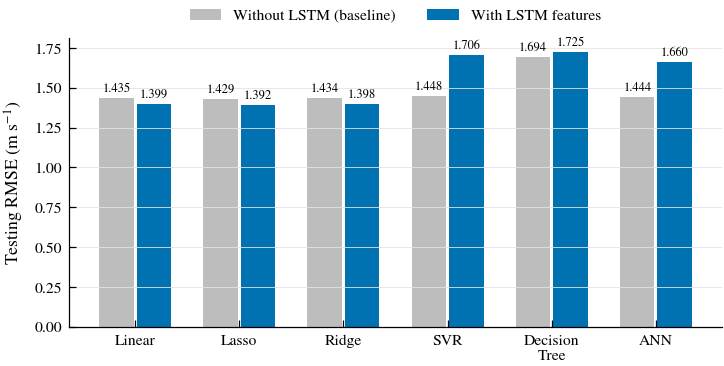

saved -> results/figures/fig06b_baseline_vs_lstm_rmse.png | .pdf | .tiff


In [19]:
# Fig 6b: RMSE testing — baseline (tanpa LSTM) vs LSTM-based, per regresor
fig, ax = plt.subplots(figsize=(COL2 * .75, 2.5))
xx = np.arange(len(MODEL_NAMES)); w = .36
vb = [RES_IDX.loc[(n, "test"), "RMSE"] for n in MODEL_NAMES]
vl = [RES_IDX.loc[(f"LSTM–{n}", "test"), "RMSE"] for n in MODEL_NAMES]
b1 = ax.bar(xx - w/2, vb, w * .92, color="#bdbdbd", label="Without LSTM (baseline)")
b2 = ax.bar(xx + w/2, vl, w * .92, color="#0072B2", label="With LSTM features")
ax.bar_label(b1, fmt="%.3f", fontsize=6, padding=1.5); ax.bar_label(b2, fmt="%.3f", fontsize=6, padding=1.5)
ax.set_xticks(xx); ax.set_xticklabels([SHORT_NAME[n] for n in MODEL_NAMES])
ax.set_ylabel("Testing RMSE (m s$^{-1}$)"); ax.grid(axis="x", visible=False)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(.5, 1.15))
save_fig(fig, "fig06b_baseline_vs_lstm_rmse")

## 10. Gambar hasil

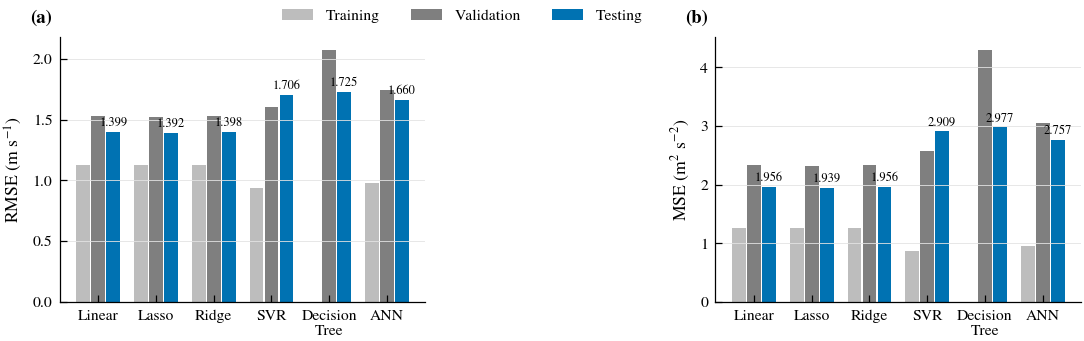

saved -> results/figures/fig06_error_comparison.png | .pdf | .tiff


In [20]:
# Fig 6: RMSE & MSE per model (train / validation / test) — indikasi overfitting
order_m = MODEL_NAMES
RES_IDX = RES.set_index(["Model", "Set"])
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.5))
set_style = {"train": ("#bdbdbd", None), "val": ("#7f7f7f", None), "test": ("#0072B2", None)}
w = .26; xx = np.arange(len(order_m))
for ax, met, lab in [(axes[0], "RMSE", "RMSE (m s$^{-1}$)"), (axes[1], "MSE", "MSE (m$^2$ s$^{-2}$)")]:
    for i, s in enumerate(["train", "val", "test"]):
        v = [RES_IDX.loc[("LSTM–" + m, s), met] for m in order_m]
        bars = ax.bar(xx + (i - 1) * w, v, w * .92, color=set_style[s][0],
                      label={"train": "Training", "val": "Validation", "test": "Testing"}[s])
        if s == "test":
            ax.bar_label(bars, fmt="%.3f", fontsize=6, padding=1.5)
    ax.set_xticks(xx); ax.set_xticklabels([SHORT_NAME[m] for m in order_m])
    ax.set_ylabel(lab); ax.grid(axis="x", visible=False)
axes[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(1.1, 1.16))
panel_label(axes[0], "a"); panel_label(axes[1], "b")
fig.tight_layout(); save_fig(fig, "fig06_error_comparison")

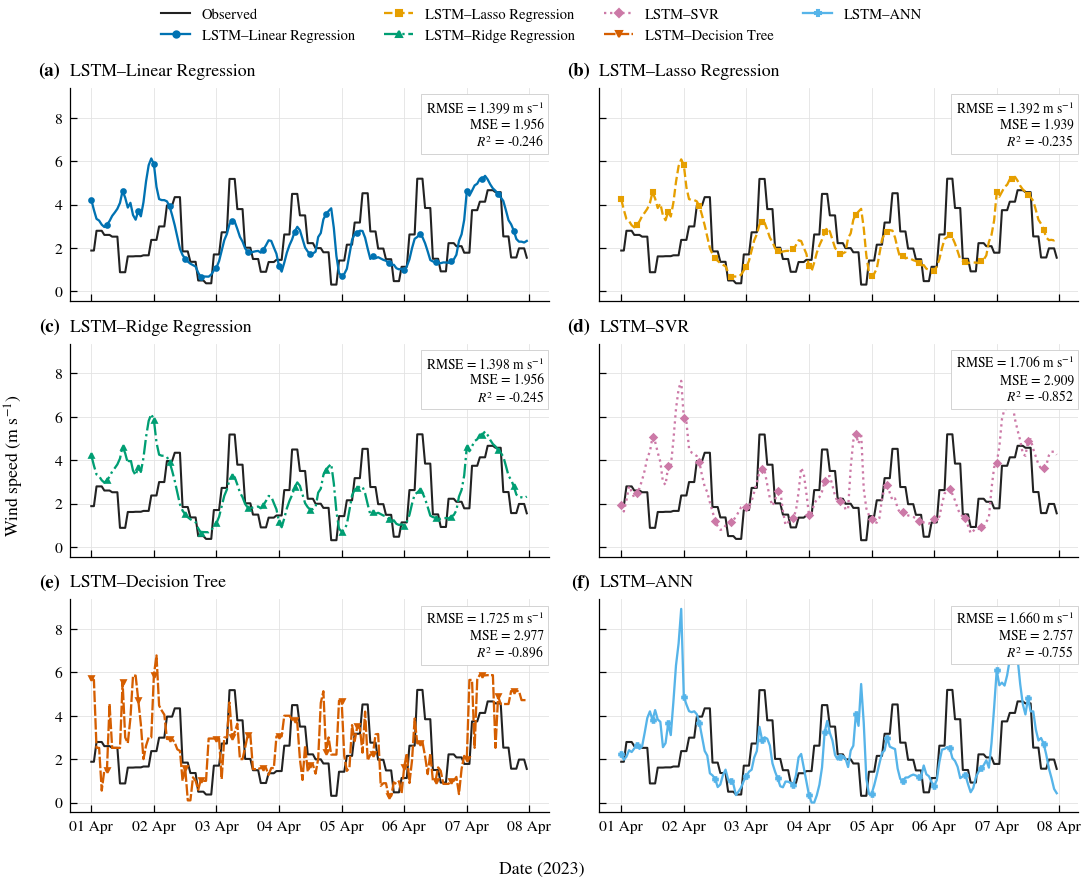

saved -> results/figures/fig07_test_week_timeseries.png | .pdf | .tiff


In [21]:
# Fig 7: observasi vs prediksi pada minggu uji (6 panel)
t = T["test"] if X_AXIS == "datetime" else np.arange(1, len(T["test"]) + 1)
fig, axes = plt.subplots(3, 2, figsize=(COL2, 5.6), sharex=True, sharey=True)
for ax, name, lab in zip(axes.ravel(), MODEL_NAMES, "abcdef"):
    ax.plot(t, Y_ms["test"], color=OBS_COLOR, lw=1.0, label="Observed")
    ax.plot(t, PRED[name]["test"], color=COLORS[name], ls=LSTYLES[name], lw=1.1,
            marker=MARKERS[name], ms=2.2, markevery=6, label="Predicted")
    m = metrics(Y_ms["test"], PRED[name]["test"])
    ax.set_title(f"LSTM–{name}", loc="left")
    ax.text(.99, .95, f"RMSE = {m['RMSE']:.3f} m s$^{{-1}}$\nMSE = {m['MSE']:.3f}\n$R^2$ = {m['R2']:.3f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=6.5,
            bbox=dict(fc="white", ec="#cccccc", lw=.4, pad=2))
    panel_label(ax, lab)
handles = [Line2D([], [], color=OBS_COLOR, lw=1.0, label="Observed")] + \
          [Line2D([], [], color=COLORS[n], ls=LSTYLES[n], marker=MARKERS[n], ms=3, lw=1.1, label=f"LSTM–{n}")
           for n in MODEL_NAMES]
fig.legend(handles=handles, ncol=4, loc="upper center", bbox_to_anchor=(.5, 1.06), fontsize=7)
def format_time_axis(axs):
    for ax in axs:
        if X_AXIS == "datetime":
            ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%d %b"))
            ax.xaxis.set_major_locator(mpl.dates.DayLocator())
        else:
            ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(24))
X_LABEL = f"Date ({T['test'][0].year})" if X_AXIS == "datetime" else "Data points (hours)"
format_time_axis(axes[-1])
fig.supylabel(LABELS[TARGET_COL], fontsize=8.5); fig.supxlabel(X_LABEL, fontsize=8.5)
fig.tight_layout(); save_fig(fig, "fig07_test_week_timeseries")

### Hasil prediksi setiap model (minggu uji, 168 data points)
Format seperti pengujian sebelumnya: kurva *Actual* vs *Predicted* per model, untuk model baseline (tanpa LSTM)
dan model LSTM-based. Juga disimpan satu gambar per model di `figures/per_model/` dan nilai prediksi di
`results/predictions_all_models_test.csv`.

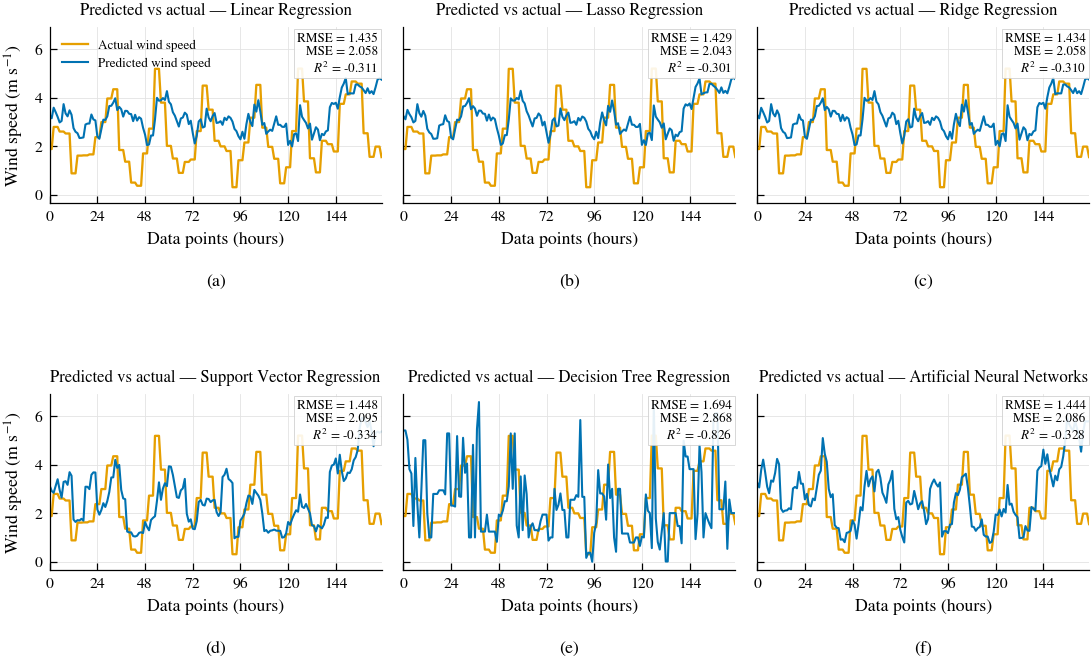

saved -> results/figures/fig07a_prediction_baseline_models.png | .pdf | .tiff


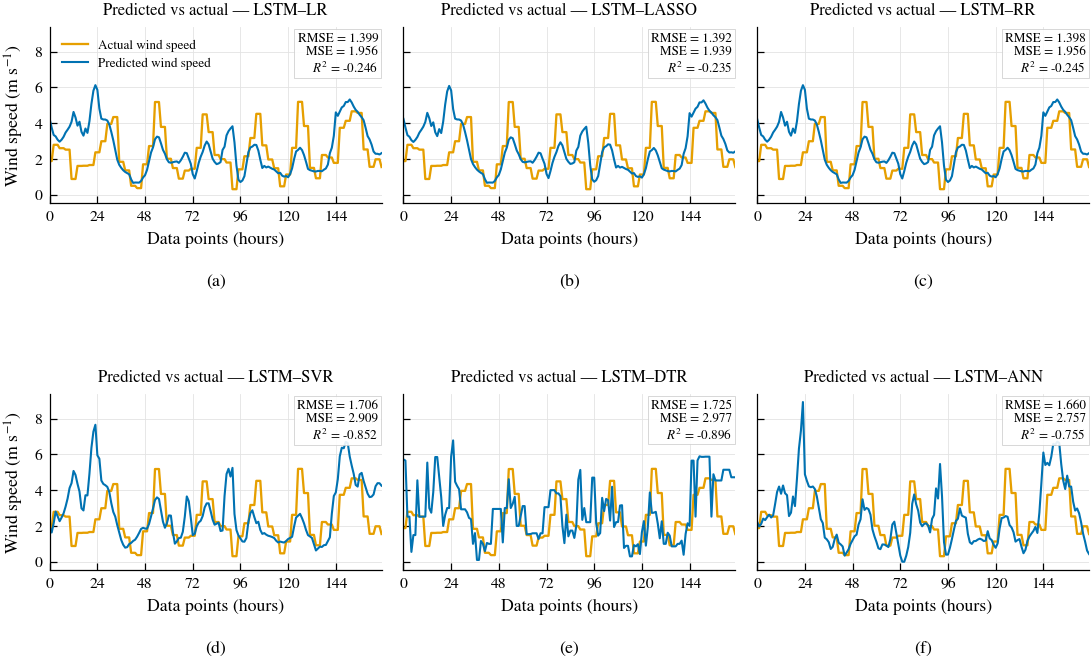

saved -> results/figures/fig07b_prediction_lstm_models.png | .pdf | .tiff
13 gambar per model -> results/figures/per_model/


,data_point,datetime,actual,LR (no LSTM),LASSO (no LSTM),RR (no LSTM),SVR (no LSTM),DTR (no LSTM),ANN (no LSTM),LSTM-LR,LSTM-LASSO,LSTM-RR,LSTM-SVR,LSTM-DTR,LSTM-ANN,LSTM standalone
0,0,2023-04-01 00:00:00,1.88,3.285,3.236,3.283,3.132,5.40,3.259,4.223,4.236,4.223,1.936,5.72,2.218,3.367
1,1,2023-04-01 01:00:00,1.88,3.146,3.105,3.144,2.912,5.40,3.057,3.751,3.757,3.750,1.632,5.65,1.974,3.026
2,2,2023-04-01 02:00:00,2.79,3.582,3.492,3.579,2.837,5.02,3.777,3.340,3.330,3.340,2.150,2.52,2.114,2.813
3,3,2023-04-01 03:00:00,2.79,3.399,3.318,3.397,3.112,3.81,4.201,3.259,3.239,3.259,2.803,2.52,2.411,2.765
4,4,2023-04-01 04:00:00,2.79,3.205,3.187,3.204,3.395,3.63,3.678,3.073,3.047,3.073,2.544,0.55,2.328,2.668
5,5,2023-04-01 05:00:00,2.60,2.975,2.975,2.975,2.955,1.47,3.093,2.965,2.949,2.965,2.266,1.49,2.492,2.593
6,6,2023-04-01 06:00:00,2.60,3.036,3.038,3.036,2.638,4.27,2.818,3.075,3.064,3.075,2.471,1.49,2.632,2.629
7,7,2023-04-01 07:00:00,2.60,3.728,3.726,3.727,3.285,2.37,3.343,3.239,3.226,3.239,2.708,4.55,2.471,2.730
8,8,2023-04-01 08:00:00,2.52,3.347,3.358,3.347,3.314,1.00,3.292,3.476,3.465,3.476,3.080,2.52,2.588,2.867
9,9,2023-04-01 09:00:00,2.52,3.225,3.212,3.225,3.164,2.93,3.650,3.632,3.627,3.632,3.525,2.52,3.220,2.945


In [22]:
os.makedirs(f"{FIG_DIR}/per_model", exist_ok=True)
xi = np.arange(len(T["test"]))                      # data points 0..167
ACT_C = "#E69F00"                                   # actual = jingga, predicted = biru (seperti gambar sebelumnya)
PRED_C = "#0072B2"

def plot_pred_panel(ax, pred, title, show_legend=True):
    ax.plot(xi, Y_ms["test"], color=ACT_C, lw=1.1, label="Actual wind speed")
    ax.plot(xi, pred, color=PRED_C, lw=1.0, label="Predicted wind speed")
    m = metrics(Y_ms["test"], pred)
    ax.set_title(title, fontsize=8)
    ax.text(.99, .97, f"RMSE = {m['RMSE']:.3f}\nMSE = {m['MSE']:.3f}\n$R^2$ = {m['R2']:.3f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=6.3,
            bbox=dict(fc="white", ec="#cccccc", lw=.4, pad=1.5, alpha=.9))
    ax.set_xlim(0, len(xi) - 1); ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(24))
    if show_legend: ax.legend(loc="upper left", fontsize=6.3)

def six_panel(pred_dict, label_fn, fname):
    fig, axes = plt.subplots(2, 3, figsize=(COL2, 4.8), sharey=True)
    for ax, n, lab in zip(axes.ravel(), MODEL_NAMES, "abcdef"):
        plot_pred_panel(ax, pred_dict[n]["test"], label_fn(n), show_legend=(lab == "a"))
        ax.set_xlabel("Data points (hours)")
        ax.text(.5, -.40, f"({lab})", transform=ax.transAxes, ha="center", va="top", fontsize=8.5)
    for ax in axes[:, 0]: ax.set_ylabel("Wind speed (m s$^{-1}$)")
    fig.tight_layout(h_pad=3.0); save_fig(fig, fname)

six_panel(BPRED, lambda n: f"Predicted vs actual — {FULL[n]}", "fig07a_prediction_baseline_models")
six_panel(PRED,  lambda n: f"Predicted vs actual — LSTM–{ABBR[n]}", "fig07b_prediction_lstm_models")

# Satu gambar per model (12 model + LSTM standalone)
singles = [(f"{FULL[n]}", BPRED[n]["test"], f"baseline_{ABBR[n]}") for n in MODEL_NAMES] + \
          [(f"LSTM–{ABBR[n]}", PRED[n]["test"], f"lstm_{ABBR[n]}") for n in MODEL_NAMES] + \
          [("LSTM (standalone)", lstm_only["test"], "lstm_standalone")]
for title, p, fn in singles:
    fig, ax = plt.subplots(figsize=(COL1 * 1.25, 2.3))
    plot_pred_panel(ax, p, f"Predicted vs actual wind speed — {title}")
    ax.set_xlabel("Data points (hours)"); ax.set_ylabel("Wind speed (m s$^{-1}$)")
    for ext in ("png", "pdf"): fig.savefig(f"{FIG_DIR}/per_model/{fn}.{ext}")
    plt.close(fig)
print(f"{len(singles)} gambar per model -> {FIG_DIR}/per_model/")

allp = pd.DataFrame({"data_point": xi, "datetime": T["test"], "actual": Y_ms["test"]})
for n in MODEL_NAMES: allp[f"{ABBR[n]} (no LSTM)"] = BPRED[n]["test"]
for n in MODEL_NAMES: allp[f"LSTM-{ABBR[n]}"] = PRED[n]["test"]
allp["LSTM standalone"] = lstm_only["test"]
allp.to_csv(f"{OUT_DIR}/predictions_all_models_test.csv", index=False)
allp.round(3).to_excel(f"{OUT_DIR}/predictions_all_models_test.xlsx", index=False)
display(allp.head(10).round(3))

### Daya angin — Persamaan (16): $P = \tfrac{1}{2} C_p \rho \frac{\pi D^2}{4} V^3$
Isi data turbin Anda (Cp, D, ρ) di bagian atas sel berikut.

Cp = 0.4 | D = 10.0 m | A = 78.54 m² | ρ = 1.225 kg/m³ (constant)
Daya aktual minggu uji: 0.001–2.690 kW | energi = 83.21 kWh


Power RMSE (kW)  \
Group                   Model                                         
Baseline (without LSTM) Linear Regression                     0.701   
                        Lasso Regression                      0.700   
                        Ridge Regression                      0.701   
                        Support Vector Regression             1.011   
                        Decision Tree Regression              1.166   
                        Artificial Neural Networks            1.014   
LSTM-based              LSTM–LR                               0.942   
                        LSTM–LASSO                            0.930   
                        LSTM–RR                               0.942   
                        LSTM–SVR                              1.510   
                        LSTM–DTR                              1.309   
                        LSTM–ANN                              1.664   

                                                    Power MAE (kW)  Power R2  \
Group                   Model                                                  
Baseline (without LSTM) Linear Regression                    0.524    -0.066   
                        Lasso Regression                     0.520    -0.064   
                        Ridge Regression                     0.524    -0.066   
                        Support Vector Regression            0.606    -1.215   
                        Decision Tree Regression             0.690    -1.948   
                        Artificial Neural Networks           0.616    -1.228   
LSTM-based              LSTM–LR                              0.572    -0.925   
                        LSTM–LASSO                           0.566    -0.877   
                        LSTM–RR                              0.572    -0.924   
                        LSTM–SVR                             0.828    -3.943   
                        LSTM–DTR                             0.820    -2.715   
                        LSTM–ANN                             0.764    -5.006   

                                                    Mean power (kW)  \
Group                   Model                                         
Baseline (without LSTM) Linear Regression                     0.714   
                        Lasso Regression                      0.714   
                        Ridge Regression                      0.713   
                        Support Vector Regression             0.609   
                        Decision Tree Regression              0.627   
                        Artificial Neural Networks            0.666   
LSTM-based              LSTM–LR                               0.608   
                        LSTM–LASSO                            0.600   
                        LSTM–RR                               0.608   
                        LSTM–SVR                              0.865   
                        LSTM–DTR                              0.867   
                        LSTM–ANN                              0.758   

                                                    Energy (kWh)  \
Group                   Model                                      
Baseline (without LSTM) Linear Regression                119.874   
                        Lasso Regression                 119.957   
                        Ridge Regression                 119.865   
                        Support Vector Regression        102.305   
                        Decision Tree Regression         105.326   
                        Artificial Neural Networks       111.834   
LSTM-based              LSTM–LR                          102.185   
                        LSTM–LASSO                       100.727   
                        LSTM–RR                          102.174   
                        LSTM–SVR                         145.345   
                        LSTM–DTR                         145.603   
                        LSTM–ANN                         

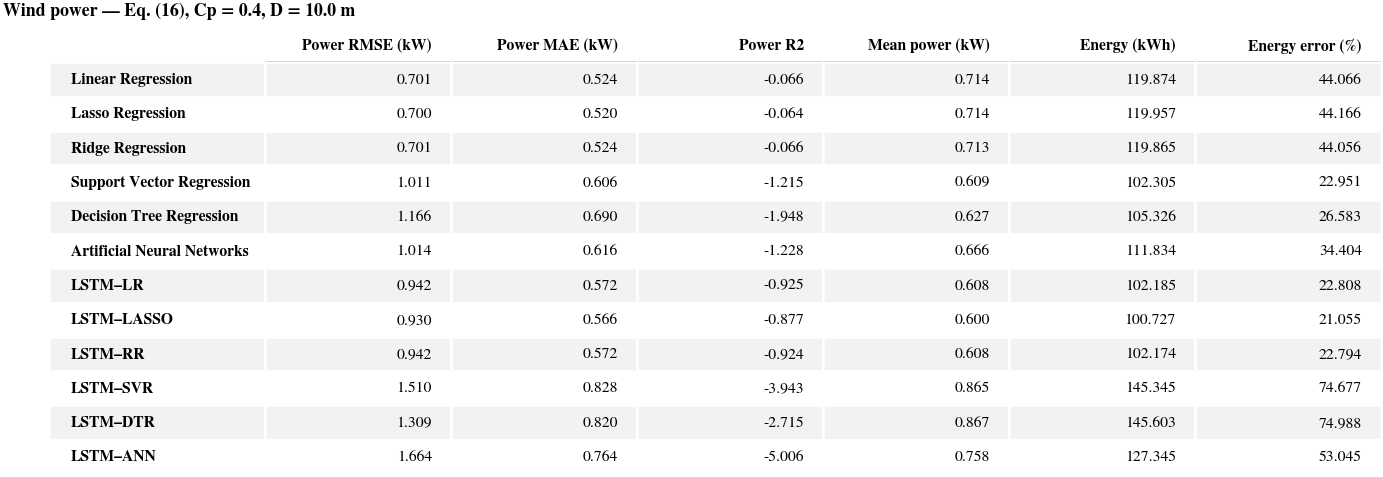

table saved -> results/figures/tables/tab07_power_eq16.png | .pdf | .xlsx


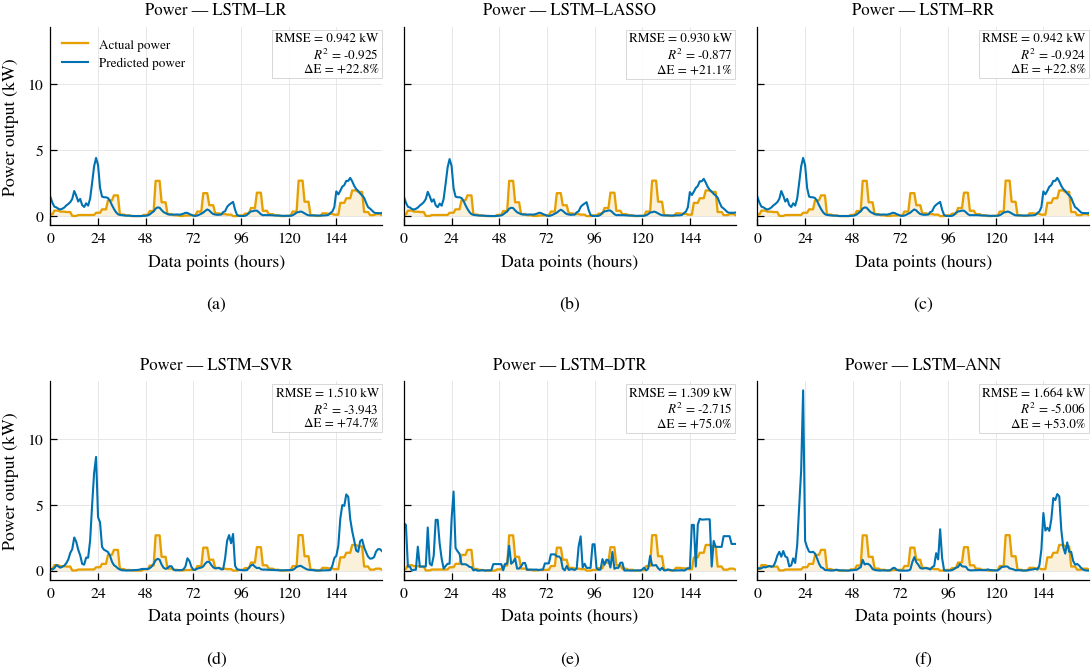

saved -> results/figures/fig14a_power_eq16_lstm_models.png | .pdf | .tiff


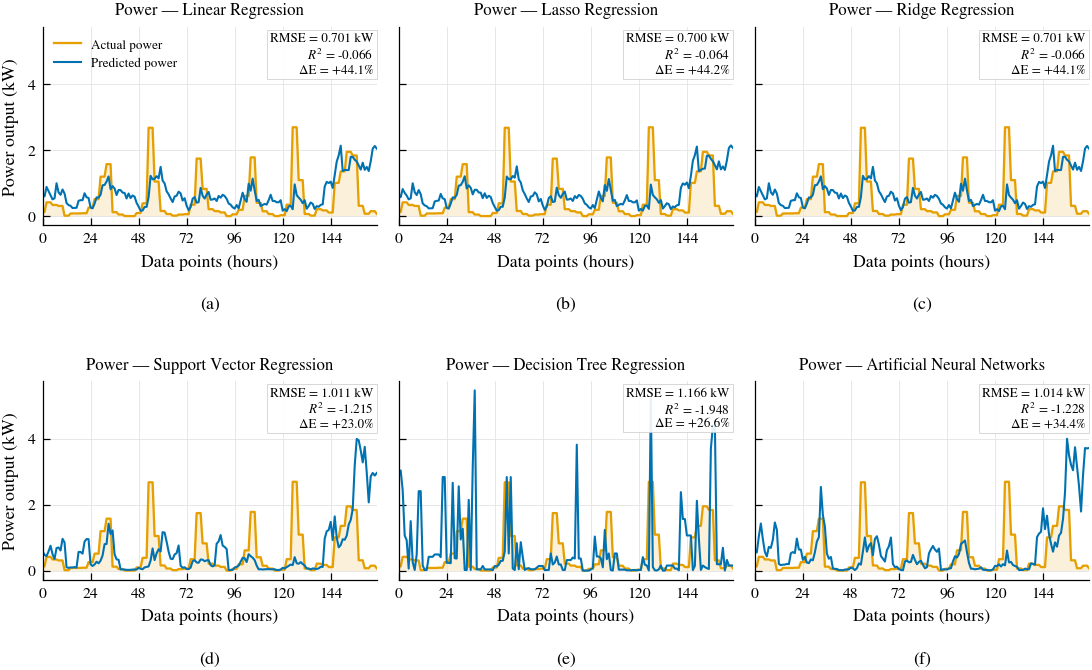

saved -> results/figures/fig14b_power_eq16_baseline_models.png | .pdf | .tiff


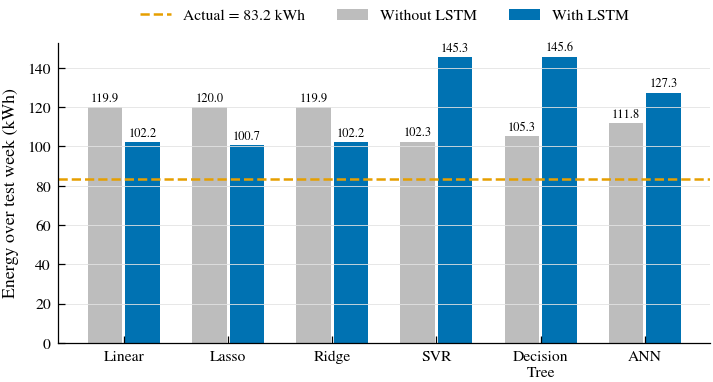

saved -> results/figures/fig15_energy_eq16_test_week.png | .pdf | .tiff


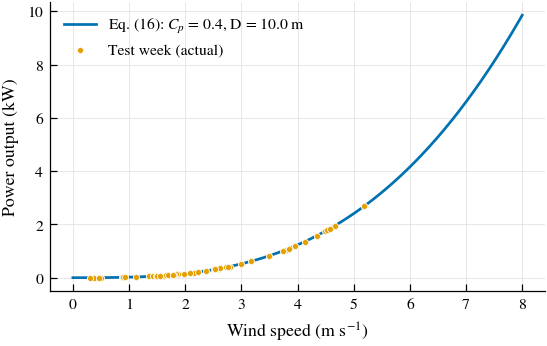

saved -> results/figures/fig16_power_curve_eq16.png | .pdf | .tiff


In [23]:
# ===================================================================================
#  WIND POWER — Eq. (16):  P = 1/2 · Cp · ρ · (π D² / 4) · V³
#  Tempel sel ini SETELAH sel "Hasil prediksi setiap model" (butuh PRED, BPRED, Y_ms, T, df)
# ===================================================================================

# ---------------- ISI DATA TURBIN ANDA ----------------
CP         = 0.40         # koefisien daya turbin (maks. teoritis Betz = 0.593)
D_ROTOR    = 10.0         # diameter rotor (m)
RHO_MODE   = "constant"   # "constant" -> pakai RHO di bawah
                          # "measured" -> ρ = p / (R_d·T) dari kolom pressure & temp_min/temp_max
RHO        = 1.225        # densitas udara (kg/m³)

V_HUB_CORRECTION = False  # True: koreksi kecepatan angin ke tinggi hub (power law)
H_REF, H_HUB, ALPHA = 10.0, 30.0, 1/7

P_RATED_KW = None         # mis. 20.0 -> daya dibatasi di rated power; None = Eq. (16) murni
V_CUT_IN   = None         # mis. 2.5 (m/s);  None = tanpa batas
V_CUT_OUT  = None         # mis. 25.0 (m/s); None = tanpa batas
# ------------------------------------------------------

AREA = np.pi * D_ROTOR ** 2 / 4                    # luas sapuan rotor (m²)

def eq16_rho(index):
    if RHO_MODE == "measured":
        d = df.reindex(index)
        t_k = d[["temp_min", "temp_max"]].mean(axis=1) + 273.15
        return (d["pressure"] * 100 / (287.05 * t_k)).fillna(RHO).values
    return np.full(len(index), RHO)

def eq16_power_kw(v, rho):
    v = np.clip(np.asarray(v, dtype=float), 0, None)
    if V_HUB_CORRECTION:
        v = v * (H_HUB / H_REF) ** ALPHA
    p = 0.5 * CP * rho * AREA * v ** 3 / 1000       # W -> kW
    if P_RATED_KW is not None: p = np.minimum(p, P_RATED_KW)
    if V_CUT_IN  is not None:  p = np.where(v < V_CUT_IN, 0.0, p)
    if V_CUT_OUT is not None:  p = np.where(v >= V_CUT_OUT, 0.0, p)
    return p

# ---------- Hitung daya: aktual & prediksi setiap model (minggu uji) ----------
rho_t  = eq16_rho(T["test"])
P_ACT  = eq16_power_kw(Y_ms["test"], rho_t)
P_LSTM = {n: eq16_power_kw(PRED[n]["test"], rho_t) for n in MODEL_NAMES}
P_BASE = {n: eq16_power_kw(BPRED[n]["test"], rho_t) for n in MODEL_NAMES}
E_ACT  = P_ACT.sum()                                # kWh (data per jam: ΣP·1 h)

print(f"Cp = {CP} | D = {D_ROTOR} m | A = {AREA:.2f} m² | ρ = {rho_t.mean():.3f} kg/m³ ({RHO_MODE})")
print(f"Daya aktual minggu uji: {P_ACT.min():.3f}–{P_ACT.max():.3f} kW | energi = {E_ACT:.2f} kWh")

rows = []
for grp, PP, lab in [("Baseline (without LSTM)", P_BASE, lambda n: FULL[n]),
                     ("LSTM-based", P_LSTM, lambda n: f"LSTM–{ABBR[n]}")]:
    for n in MODEL_NAMES:
        m = metrics(P_ACT, PP[n])
        rows.append({"Group": grp, "Model": lab(n),
                     "Power RMSE (kW)": m["RMSE"], "Power MAE (kW)": m["MAE"], "Power R2": m["R2"],
                     "Mean power (kW)": PP[n].mean(), "Energy (kWh)": PP[n].sum(),
                     "Energy error (%)": (PP[n].sum() - E_ACT) / E_ACT * 100 if E_ACT > 0 else np.nan})
EQ16_TBL = pd.DataFrame(rows)
EQ16_TBL.to_csv(f"{OUT_DIR}/power_eq16_metrics.csv", index=False)
EQ16_TBL.round(3).to_excel(f"{OUT_DIR}/power_eq16_metrics.xlsx", index=False)
display(EQ16_TBL.set_index(["Group", "Model"]).round(3))
save_table_image(EQ16_TBL.set_index("Model").drop(columns="Group"), "tab07_power_eq16",
                 f"Wind power — Eq. (16), Cp = {CP}, D = {D_ROTOR} m", decimals=3)

pw = pd.DataFrame({"data_point": np.arange(len(P_ACT)), "datetime": T["test"], "rho": rho_t,
                   "wind_actual": Y_ms["test"], "power_actual_kW": P_ACT})
for n in MODEL_NAMES: pw[f"power_{ABBR[n]}_noLSTM_kW"] = P_BASE[n]
for n in MODEL_NAMES: pw[f"power_LSTM-{ABBR[n]}_kW"] = P_LSTM[n]
pw.to_csv(f"{OUT_DIR}/power_eq16_predictions_test.csv", index=False)

# ---------- Fig 14: daya aktual vs prediksi per model (6 panel) ----------
xi = np.arange(len(P_ACT))
def power_six_panel(PP, label_fn, fname):
    fig, axes = plt.subplots(2, 3, figsize=(COL2, 4.8), sharey=True)
    for ax, n, lab in zip(axes.ravel(), MODEL_NAMES, "abcdef"):
        ax.fill_between(xi, P_ACT, color="#E69F00", alpha=.15, lw=0)
        ax.plot(xi, P_ACT, color="#E69F00", lw=1.1, label="Actual power")
        ax.plot(xi, PP[n], color="#0072B2", lw=1.0, label="Predicted power")
        m = metrics(P_ACT, PP[n]); e = (PP[n].sum() - E_ACT) / E_ACT * 100 if E_ACT > 0 else np.nan
        ax.text(.99, .97, f"RMSE = {m['RMSE']:.3f} kW\n$R^2$ = {m['R2']:.3f}\nΔE = {e:+.1f}%",
                transform=ax.transAxes, ha="right", va="top", fontsize=6.3,
                bbox=dict(fc="white", ec="#cccccc", lw=.4, pad=1.5, alpha=.9))
        ax.set_title(label_fn(n), fontsize=8); ax.set_xlim(0, len(xi) - 1)
        ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(24))
        ax.set_xlabel("Data points (hours)")
        ax.text(.5, -.36, f"({lab})", transform=ax.transAxes, ha="center", va="top", fontsize=8.5)
        if lab == "a": ax.legend(loc="upper left", fontsize=6.3)
    for ax in axes[:, 0]: ax.set_ylabel("Power output (kW)")
    fig.tight_layout(h_pad=1.5); save_fig(fig, fname)

power_six_panel(P_LSTM, lambda n: f"Power — LSTM–{ABBR[n]}", "fig14a_power_eq16_lstm_models")
power_six_panel(P_BASE, lambda n: f"Power — {FULL[n]}", "fig14b_power_eq16_baseline_models")

# ---------- Fig 15: energi total minggu uji (baseline vs LSTM) ----------
fig, ax = plt.subplots(figsize=(COL2 * .75, 2.6))
xx = np.arange(len(MODEL_NAMES)); w = .36
eb = [P_BASE[n].sum() for n in MODEL_NAMES]; el = [P_LSTM[n].sum() for n in MODEL_NAMES]
b1 = ax.bar(xx - w/2, eb, w * .92, color="#bdbdbd", label="Without LSTM")
b2 = ax.bar(xx + w/2, el, w * .92, color="#0072B2", label="With LSTM")
ax.axhline(E_ACT, color="#E69F00", lw=1.2, ls="--", label=f"Actual = {E_ACT:.1f} kWh")
ax.bar_label(b1, fmt="%.1f", fontsize=6, padding=1.5); ax.bar_label(b2, fmt="%.1f", fontsize=6, padding=1.5)
ax.set_xticks(xx); ax.set_xticklabels([SHORT_NAME[n] for n in MODEL_NAMES])
ax.set_ylabel("Energy over test week (kWh)"); ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, 1.16))
save_fig(fig, "fig15_energy_eq16_test_week")

# ---------- Fig 16: kurva P–V Eq. (16) + titik operasi minggu uji ----------
vv = np.linspace(0, max(8, Y_ms["test"].max() * 1.3), 300)
fig, ax = plt.subplots(figsize=(COL1 * 1.2, 2.5))
ax.plot(vv, eq16_power_kw(vv, np.full_like(vv, rho_t.mean())), color="#0072B2", lw=1.3,
        label=rf"Eq. (16): $C_p$ = {CP}, D = {D_ROTOR} m")
ax.scatter(Y_ms["test"], P_ACT, s=8, color="#E69F00", ec="white", lw=.3, zorder=3, label="Test week (actual)")
ax.set_xlabel("Wind speed (m s$^{-1}$)"); ax.set_ylabel("Power output (kW)"); ax.legend(loc="upper left")
save_fig(fig, "fig16_power_curve_eq16")

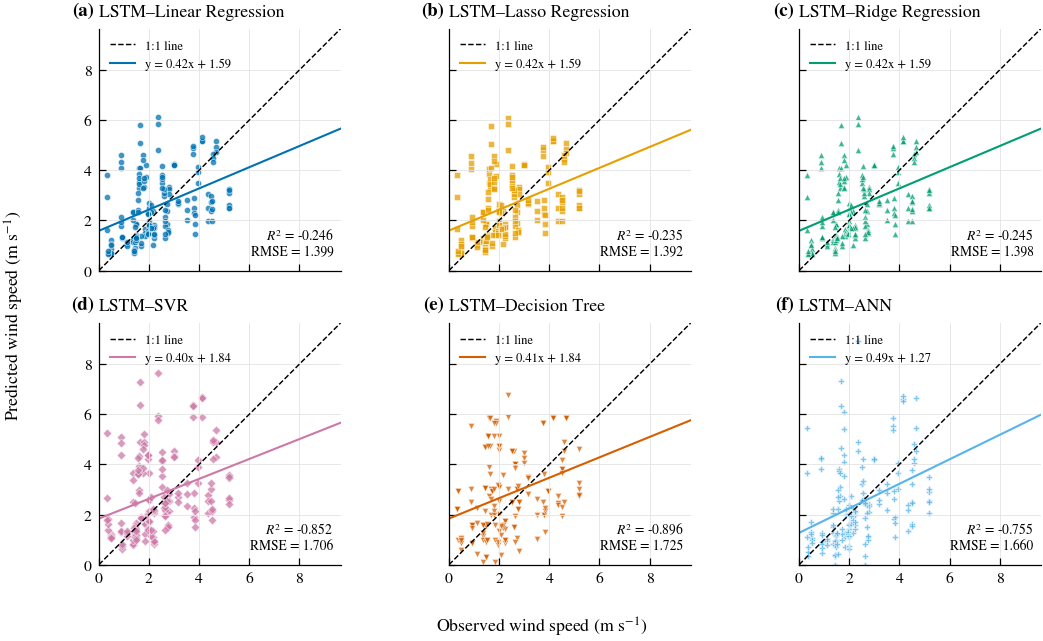

saved -> results/figures/fig08_scatter_observed_predicted.png | .pdf | .tiff


In [24]:
# Fig 8: scatter observed vs predicted dengan garis 1:1 dan regresi
lim = [0, max(Y_ms["test"].max(), max(PRED[n]["test"].max() for n in MODEL_NAMES)) * 1.08]
fig, axes = plt.subplots(2, 3, figsize=(COL2, 4.4), sharex=True, sharey=True)
for ax, name, lab in zip(axes.ravel(), MODEL_NAMES, "abcdef"):
    y, p = Y_ms["test"], PRED[name]["test"]
    ax.scatter(y, p, s=9, color=COLORS[name], marker=MARKERS[name], alpha=.75, lw=.3, ec="white")
    ax.plot(lim, lim, color="black", lw=.7, ls="--", label="1:1 line")
    k, b = np.polyfit(y, p, 1)
    ax.plot(lim, np.array(lim) * k + b, color=COLORS[name], lw=1, label=f"y = {k:.2f}x + {b:.2f}")
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
    ax.set_title(f"LSTM–{name}", loc="left")
    ax.text(.97, .05, f"$R^2$ = {r2_score(y, p):.3f}\nRMSE = {np.sqrt(mean_squared_error(y, p)):.3f}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=6.5)
    ax.legend(loc="upper left", fontsize=6); panel_label(ax, lab)
fig.supxlabel("Observed wind speed (m s$^{-1}$)", fontsize=8.5)
fig.supylabel("Predicted wind speed (m s$^{-1}$)", fontsize=8.5)
fig.tight_layout(); save_fig(fig, "fig08_scatter_observed_predicted")

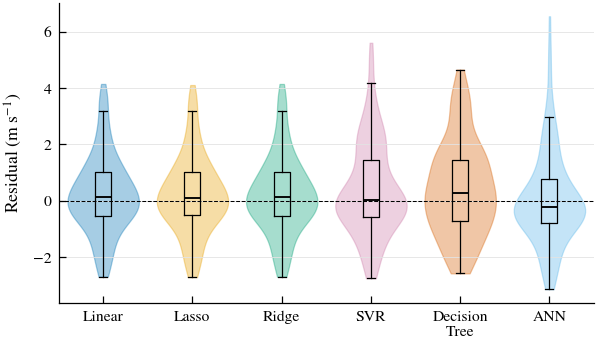

saved -> results/figures/fig09_residual_distribution.png | .pdf | .tiff


In [25]:
# Fig 9: distribusi residual (prediksi - observasi) pada minggu uji
resid = [PRED[n]["test"] - Y_ms["test"] for n in MODEL_NAMES]
fig, ax = plt.subplots(figsize=(COL1 * 1.3, 2.6))
vp = ax.violinplot(resid, showextrema=False, widths=.8)
for body, n in zip(vp["bodies"], MODEL_NAMES):
    body.set_facecolor(COLORS[n]); body.set_alpha(.35); body.set_edgecolor(COLORS[n]); body.set_linewidth(.6)
ax.boxplot(resid, widths=.18, showfliers=False, medianprops=dict(color="black", lw=.9),
           boxprops=dict(lw=.6), whiskerprops=dict(lw=.6), capprops=dict(lw=.6))
ax.axhline(0, color="black", lw=.5, ls="--")
ax.set_xticks(range(1, len(MODEL_NAMES) + 1))
ax.set_xticklabels([SHORT_NAME[m] for m in MODEL_NAMES])
ax.set_ylabel("Residual (m s$^{-1}$)"); ax.grid(axis="x", visible=False)
save_fig(fig, "fig09_residual_distribution")

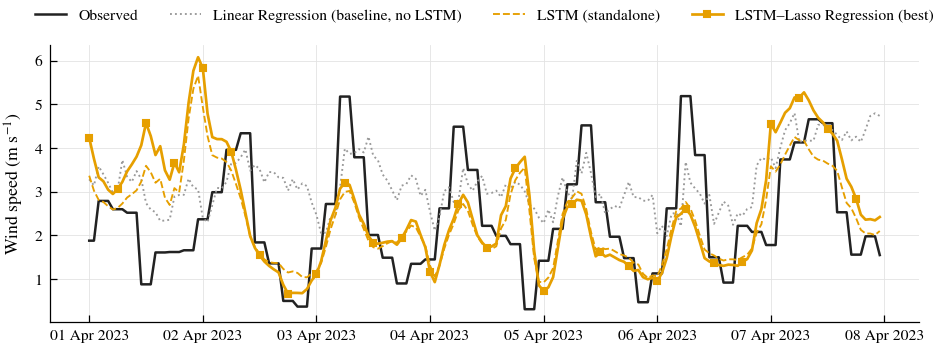

saved -> results/figures/fig10_best_model_vs_baselines.png | .pdf | .tiff


In [26]:
# Fig 10: model terbaik vs pembanding (baseline & LSTM standalone)
fig, ax = plt.subplots(figsize=(COL2, 2.4))
t = T["test"]
ax.plot(t, Y_ms["test"], color=OBS_COLOR, lw=1.2, label="Observed")
ax.plot(t, lr_only["test"], color="#999999", lw=.9, ls=":", label="Linear Regression (baseline, no LSTM)")
ax.plot(t, lstm_only["test"], color="#E69F00", lw=.9, ls="--", label="LSTM (standalone)")
ax.plot(t, PRED[BEST]["test"], color=COLORS[BEST], lw=1.3, marker=MARKERS[BEST], ms=2.5, markevery=6,
        label=f"LSTM–{BEST} (best)")
ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%d %b %Y")); ax.xaxis.set_major_locator(mpl.dates.DayLocator())
ax.set_ylabel(LABELS[TARGET_COL]); ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(.5, 1.18))
save_fig(fig, "fig10_best_model_vs_baselines")

## 10b. Prediksi daya angin (wind power)
Kecepatan angin (observasi & prediksi tiap model) dikonversi ke daya:
1. **Koreksi tinggi hub** — power law: $v_{hub} = v_{ref}\,(h_{hub}/h_{ref})^{\alpha}$
2. **Densitas udara** dari tekanan & suhu terukur: $\rho = p / (R_d\,T)$, $R_d$ = 287.05 J kg⁻¹ K⁻¹
3. **Wind power density**: $WPD = \tfrac{1}{2}\rho v^3$ (W m⁻²)
4. **Daya turbin** dari model kurva daya kubik:
   $P = P_r \dfrac{v^3 - v_{ci}^3}{v_r^3 - v_{ci}^3}\cdot\dfrac{\rho}{1.225}$ untuk $v_{ci} \le v < v_r$, $P_r$ untuk $v_r \le v < v_{co}$, 0 di luar itu
   (atau interpolasi kurva daya pabrikan bila `POWER_CURVE_CSV` diisi).

Daya "aktual" = daya yang dihitung dari kecepatan angin observasi (estimated actual power).

In [27]:
R_D = 287.05

def air_density(index):
    d = df.reindex(index)
    p = d["pressure"] * 100 if "pressure" in d else pd.Series(101325.0, index=index)
    tc = d[["temp_min", "temp_max"]].mean(axis=1) if {"temp_min", "temp_max"} <= set(d.columns) else 15.0
    return (p / (R_D * (tc + 273.15))).fillna(1.225).values

def to_hub(v): return np.asarray(v) * (HUB_HEIGHT / MEAS_HEIGHT) ** SHEAR_ALPHA

if POWER_CURVE_CSV:
    pc = pd.read_csv(POWER_CURVE_CSV).sort_values("speed")
    def turbine_power(v, rho):
        p = np.interp(v, pc.speed, pc.power_kw, left=0, right=0)
        return p * rho / 1.225                     # koreksi densitas (IEC 61400-12)
else:
    def turbine_power(v, rho):
        v = np.asarray(v, dtype=float); tb = TURBINE
        vci, vr, pr = tb["cut_in"], tb["rated_speed"], tb["rated_power_kw"]
        p = pr * (v ** 3 - vci ** 3) / (vr ** 3 - vci ** 3) * np.asarray(rho) / 1.225   # kW
        p = np.minimum(p, pr)
        p = np.where((v >= vr) & (v < tb["cut_out"]), pr, p)
        return np.where((v < tb["cut_in"]) | (v >= tb["cut_out"]), 0.0, p)

def wpd(v, rho): return 0.5 * rho * np.asarray(v) ** 3     # W/m^2

rho_te = air_density(T["test"])
vhub_obs = to_hub(Y_ms["test"])
POW = {"Observed": turbine_power(vhub_obs, rho_te)}
WPD = {"Observed": wpd(vhub_obs, rho_te)}
VHUB = {"Observed": vhub_obs}
for n in MODEL_NAMES:
    vh = to_hub(PRED[n]["test"])
    VHUB[n], POW[n], WPD[n] = vh, turbine_power(vh, rho_te), wpd(vh, rho_te)

print(f"Densitas udara minggu uji: {rho_te.mean():.3f} ± {rho_te.std():.3f} kg m^-3")
print(f"Wind speed hub ({HUB_HEIGHT:.0f} m) observasi: {vhub_obs.min():.2f}–{vhub_obs.max():.2f} m/s; "
      f"jam di atas cut-in ({TURBINE['cut_in']} m/s): {(vhub_obs >= TURBINE['cut_in']).sum()} dari {len(vhub_obs)}")

rows = []
E_obs = POW["Observed"].sum()                 # kWh (data per jam)
for n in MODEL_NAMES:
    mp, mw = metrics(POW["Observed"], POW[n]), metrics(WPD["Observed"], WPD[n])
    rows.append({"Model": f"LSTM–{n}",
                 "Power RMSE (kW)": mp["RMSE"], "Power MAE (kW)": mp["MAE"], "Power R2": mp["R2"],
                 "WPD RMSE (W/m2)": mw["RMSE"], "WPD R2": mw["R2"],
                 "Energy predicted (kWh)": POW[n].sum(), "Energy observed (kWh)": E_obs,
                 "Energy error (%)": (POW[n].sum() - E_obs) / E_obs * 100 if E_obs > 0 else np.nan})
POWER_TBL = pd.DataFrame(rows).set_index("Model").sort_values("Power RMSE (kW)")
POWER_TBL.to_csv(f"{OUT_DIR}/metrics_power_test.csv")
display(POWER_TBL.round(3))

pred_out = pd.DataFrame({"datetime": T["test"], "air_density": rho_te,
                         "wind_obs": Y_ms["test"], "wind_hub_obs": vhub_obs,
                         "power_obs_kW": POW["Observed"], "wpd_obs_Wm2": WPD["Observed"]})
for n in MODEL_NAMES:
    k = n.replace(" Regression", "").replace(" ", "")
    pred_out[f"wind_pred_{k}"] = PRED[n]["test"]
    pred_out[f"power_pred_{k}_kW"] = POW[n]
    pred_out[f"wpd_pred_{k}_Wm2"] = WPD[n]
pred_out.to_csv(f"{OUT_DIR}/wind_and_power_predictions_test.csv", index=False)
print(f"-> {OUT_DIR}/wind_and_power_predictions_test.csv")

Densitas udara minggu uji: 1.194 ± 0.013 kg m^-3
Wind speed hub (30 m) observasi: 0.36–6.07 m/s; jam di atas cut-in (2.5 m/s): 81 dari 168


,Power RMSE (kW),Power MAE (kW),Power R2,WPD RMSE (W/m2),WPD R2,Energy predicted (kWh),Energy observed (kWh),Energy error (%)
Model,,,,,,,,
LSTM–Lasso Regression,1.119,0.642,-1.032,46.273,-0.918,96.725,75.454,28.191
LSTM–Ridge Regression,1.134,0.650,-1.085,46.866,-0.967,98.581,75.454,30.651
LSTM–Linear Regression,1.134,0.650,-1.085,46.872,-0.968,98.595,75.454,30.670
LSTM–Decision Tree,1.589,0.947,-3.095,65.411,-2.832,151.961,75.454,101.396
LSTM–SVR,1.846,0.970,-4.529,75.553,-4.113,152.217,75.454,101.736
LSTM–ANN,2.044,0.882,-5.776,83.332,-5.220,133.589,75.454,77.047


-> results/wind_and_power_predictions_test.csv


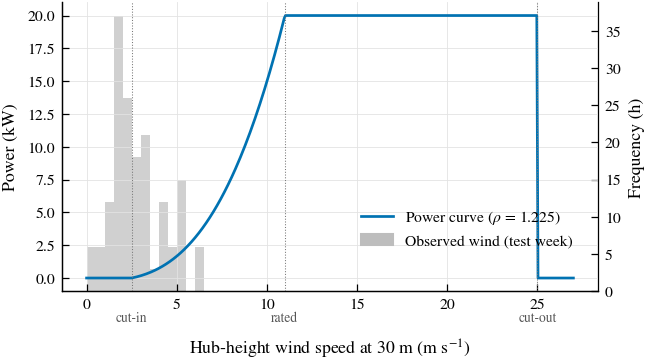

saved -> results/figures/fig11_power_curve_wind_distribution.png | .pdf | .tiff


In [28]:
# Fig 11: kurva daya turbin + distribusi wind speed hub-height minggu uji
vv = np.linspace(0, max(TURBINE["cut_out"] + 2, vhub_obs.max() + 1), 400)
fig, ax = plt.subplots(figsize=(COL1 * 1.3, 2.5))
ax2 = ax.twinx()
ax2.hist(vhub_obs, bins=np.arange(0, vv.max() + .5, .5), color="#bdbdbd", alpha=.7, zorder=0)
ax2.set_ylabel("Frequency (h)"); ax2.spines["right"].set_visible(True); ax2.grid(False)
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.plot(vv, turbine_power(vv, 1.225), color="#0072B2", lw=1.3)
for x, l in [(TURBINE["cut_in"], "cut-in"), (TURBINE["rated_speed"], "rated"), (TURBINE["cut_out"], "cut-out")]:
    ax.axvline(x, color="#777", lw=.5, ls=":")
    ax.text(x, -0.07, l, transform=ax.get_xaxis_transform(), fontsize=6.5, ha="center", va="top", color="#555")
ax.set_xlabel(f"Hub-height wind speed at {HUB_HEIGHT:.0f} m (m s$^{{-1}}$)", labelpad=12); ax.set_ylabel("Power (kW)")
ax.legend(handles=[Line2D([], [], color="#0072B2", lw=1.3, label="Power curve ($\\rho$ = 1.225)"),
                   mpl.patches.Patch(color="#bdbdbd", label="Observed wind (test week)")],
          loc="lower right", bbox_to_anchor=(.98, .1))
save_fig(fig, "fig11_power_curve_wind_distribution")

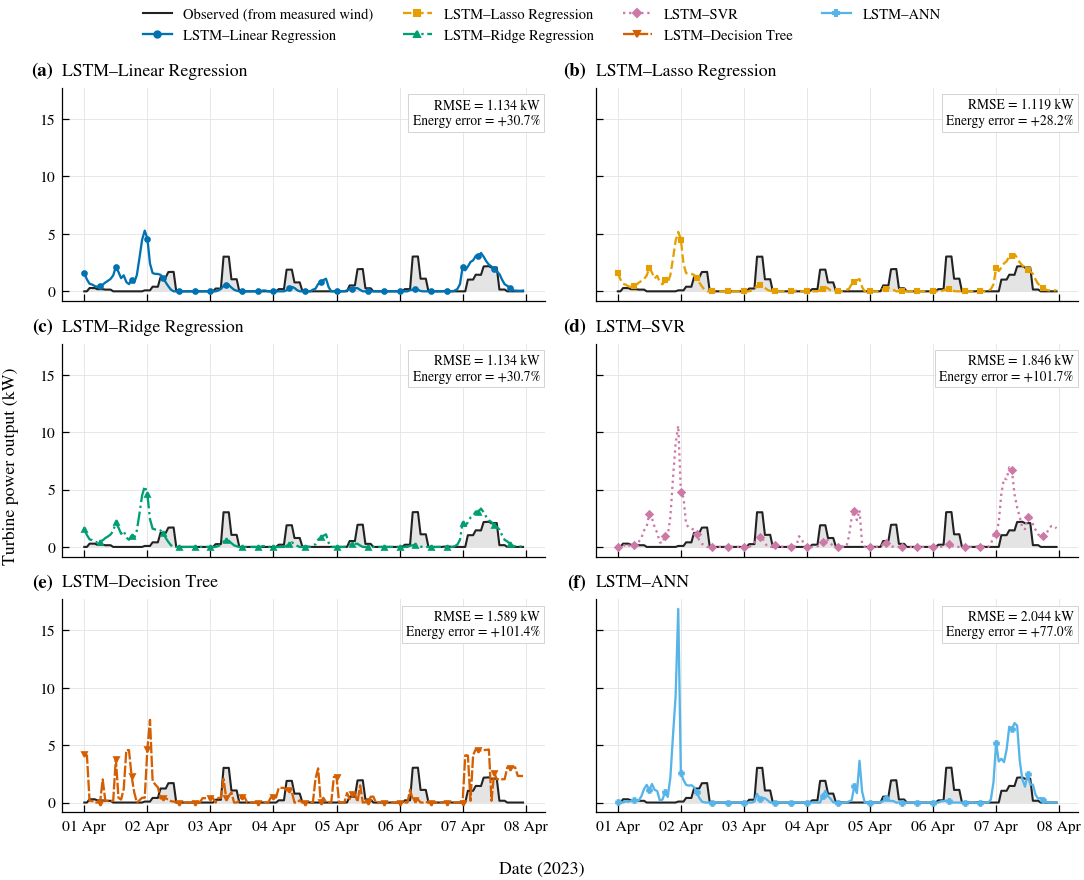

saved -> results/figures/fig12_power_prediction_test_week.png | .pdf | .tiff


In [29]:
# Fig 12: prediksi vs observasi daya turbin pada minggu uji (6 panel)
t = T["test"] if X_AXIS == "datetime" else np.arange(1, len(T["test"]) + 1)
fig, axes = plt.subplots(3, 2, figsize=(COL2, 5.6), sharex=True, sharey=True)
for ax, name, lab in zip(axes.ravel(), MODEL_NAMES, "abcdef"):
    ax.fill_between(t, POW["Observed"], color=OBS_COLOR, alpha=.12, lw=0, step=None)
    ax.plot(t, POW["Observed"], color=OBS_COLOR, lw=1.0)
    ax.plot(t, POW[name], color=COLORS[name], ls=LSTYLES[name], lw=1.1, marker=MARKERS[name], ms=2.2, markevery=6)
    r = POWER_TBL.loc[f"LSTM–{name}"]
    ax.set_title(f"LSTM–{name}", loc="left")
    ax.text(.99, .95, f"RMSE = {r['Power RMSE (kW)']:.3f} kW\nEnergy error = {r['Energy error (%)']:+.1f}%",
            transform=ax.transAxes, ha="right", va="top", fontsize=6.5,
            bbox=dict(fc="white", ec="#cccccc", lw=.4, pad=2))
    panel_label(ax, lab)
handles = [Line2D([], [], color=OBS_COLOR, lw=1.0, label="Observed (from measured wind)")] + \
          [Line2D([], [], color=COLORS[n], ls=LSTYLES[n], marker=MARKERS[n], ms=3, lw=1.1, label=f"LSTM–{n}")
           for n in MODEL_NAMES]
fig.legend(handles=handles, ncol=4, loc="upper center", bbox_to_anchor=(.5, 1.06), fontsize=7)
format_time_axis(axes[-1])
fig.supylabel("Turbine power output (kW)", fontsize=8.5); fig.supxlabel(X_LABEL, fontsize=8.5)
fig.tight_layout(); save_fig(fig, "fig12_power_prediction_test_week")

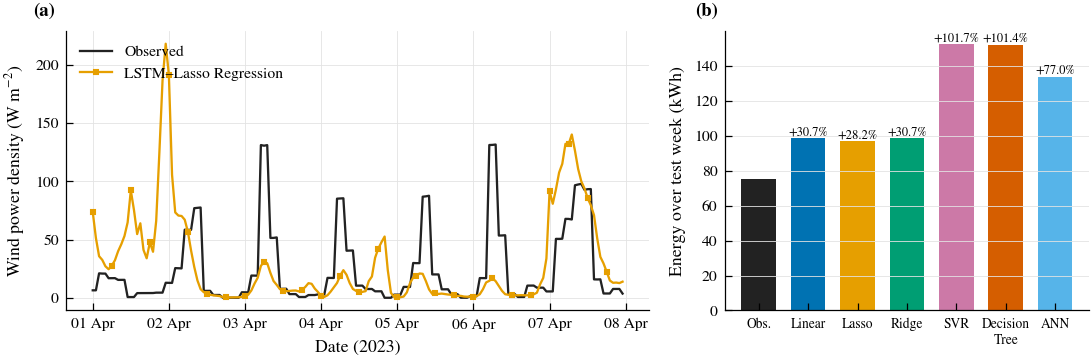

saved -> results/figures/fig13_wind_power_density_energy.png | .pdf | .tiff


In [30]:
# Fig 13: (a) wind power density & (b) energi total minggu uji per model
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.6), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax = axes[0]
tt = T["test"] if X_AXIS == "datetime" else np.arange(1, len(T["test"]) + 1)
ax.plot(tt, WPD["Observed"], color=OBS_COLOR, lw=1.1, label="Observed")
ax.plot(tt, WPD[BEST], color=COLORS[BEST], lw=1.1, marker=MARKERS[BEST], ms=2.2, markevery=6, label=f"LSTM–{BEST}")
ax.set_ylabel("Wind power density (W m$^{-2}$)"); ax.set_xlabel(X_LABEL); ax.legend(loc="upper left")
format_time_axis([ax]); panel_label(ax, "a")

ax = axes[1]
names = ["Observed"] + MODEL_NAMES
E = [POW[n].sum() for n in names]
bars = ax.bar(range(len(names)), E, color=[OBS_COLOR] + [COLORS[n] for n in MODEL_NAMES], width=.7)
for b, n in zip(bars[1:], MODEL_NAMES):
    err = POWER_TBL.loc[f"LSTM–{n}", "Energy error (%)"]
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{err:+.1f}%", ha="center", va="bottom", fontsize=6)
ax.set_xticks(range(len(names))); ax.set_xticklabels(["Obs."] + [SHORT_NAME[n] for n in MODEL_NAMES], fontsize=6.5)
ax.set_ylabel("Energy over test week (kWh)"); ax.grid(axis="x", visible=False); panel_label(ax, "b")
fig.tight_layout(); save_fig(fig, "fig13_wind_power_density_energy")

## 11. Simpan model untuk deployment & unduh semua hasil

In [31]:
extractor.save(f"{OUT_DIR}/lstm_feature_extractor.keras")
joblib.dump({"regressors": fitted, "best": BEST, "feat_scaler": feat_scaler,
             "x_scaler": x_scaler, "y_scaler": y_scaler}, f"{OUT_DIR}/stage2_bundle.joblib")
json.dump({"input_cols": INPUT_COLS, "window": WINDOW, "horizon": HORIZON, "target": TARGET_COL,
           "best_model": BEST, "wind_deg_sincos": WIND_DEG_SINCOS}, open(f"{OUT_DIR}/config.json", "w"), indent=2)
pd.DataFrame({"datetime": T["test"], "observed": Y_ms["test"],
              **{f"LSTM-{n}": PRED[n]["test"] for n in MODEL_NAMES},
              "LSTM_standalone": lstm_only["test"], "LR_no_LSTM": lr_only["test"]}
             ).to_csv(f"{OUT_DIR}/test_week_predictions.csv", index=False)

def predict_next_hour(history_df):
    # history_df: >= WINDOW jam terakhir yang sudah dipreprocess (kolom = INPUT_COLS)
    x = x_scaler.transform(history_df[INPUT_COLS].tail(WINDOW))[None].astype("float32")
    f = feat_scaler.transform(extractor.predict(x, verbose=0))
    return float(to_ms(fitted[BEST].predict(f))[0])

hist_df = df.dropna().loc[:test_end]
v_next = predict_next_hour(hist_df)
rho_last = air_density(hist_df.index[-1:])
p_next = float(turbine_power(to_hub([v_next]), rho_last)[0])
print(f"Prediksi 1 jam setelah {hist_df.index[-1]}: wind = {v_next:.3f} m/s "
      f"(hub {to_hub(v_next):.3f} m/s) -> power = {p_next:.3f} kW")

TIMING["run_end"] = datetime.datetime.now().isoformat(timespec="seconds")
RUN_SUMMARY = {"run_id": RUN_ID, "timing": TIMING, "input_cols": INPUT_COLS,
               "input_shape": list(X["train"].shape[1:]), "best_model": f"LSTM–{BEST}",
               "samples": {k: int(len(X[k])) for k in SETS},
               "test_metrics": RES_IDX.xs("test", level="Set").round(4).to_dict(orient="index")}
json.dump(RUN_SUMMARY, open(f"{LOG_DIR}/run_summary.json", "w"), indent=2, default=str)
print(f"Run summary -> {LOG_DIR}/run_summary.json")

shutil.make_archive("wind_lstm_results", "zip", OUT_DIR)
print("Arsip: wind_lstm_results.zip")
if IN_COLAB:
    from google.colab import files
    files.download("wind_lstm_results.zip")

Prediksi 1 jam setelah 2023-04-07 23:00:00: wind = 2.550 m/s (hub 2.984 m/s) -> power = 0.165 kW
Run summary -> results/logs/run_summary.json
Arsip: wind_lstm_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>